# Практика 1. Качественный анализ динамики осцилляторов
### Домашнее задание 1, часть 2: компьютерное моделирование

В этом ноутбуке подробно разобрано, **как провести качественный анализ динамики** четырёх осцилляторов:

| № | Система | Название |
|---|---|---|
| 1 | $\ddot x + \omega^2 x = 0$ | гармонический осциллятор без трения |
| 2 | $\ddot x + 2\delta\dot x + \omega^2 x = 0$ | гармонический осциллятор с трением |
| 3 | $\ddot x + \omega^2\sin x = 0$ | ангармонический осциллятор (математический маятник) без трения |
| 4 | $\ddot x + 2\delta\dot x + \omega^2\sin x = 0$ | ангармонический осциллятор (маятник) с трением |

Задание требует для каждой системы выполнить семь пунктов. Таблица показывает, в каком месте ноутбука разобран каждый пункт.

| Пункт задания | Где в ноутбуке |
|---|---|
| 1. Особые точки аналитически | шаг «Особые точки» в каждом разделе (символьные вычисления `sympy`) |
| 2. Устойчивость по Ляпунову, характер особых точек, поведение траекторий рядом | шаг «Линеаризация и устойчивость» |
| 3. Первый интеграл (энергия), 3D-поверхности энергии, фазовые портреты, направление движения | шаги «Первый интеграл» и «3D-поверхность и фазовый портрет» (для консервативных систем) |
| 4. Потенциальная функция и её связь с фазовым портретом | шаг «Потенциал» (для консервативных систем) |
| 5. Приближённые решения при разных начальных условиях | шаг «Решения» |
| 6. Графики $x(t)$, $\dot x(t)$ и контуры на фазовой плоскости | шаг «Решения» (рисунки с тремя панелями) |
| 7. Содержательные выводы | раздел 6 |

**Как читать этот ноутбук.**

1. Раздел 1 — теория, которой достаточно для всего остального. Если какой-то шаг в разделах 2–5 кажется «из воздуха», ответ лежит в разделе 1.
2. Разделы 2–5 устроены одинаково: уравнение → особые точки → линеаризация и устойчивость → (для консервативных) энергия и потенциал → решения и графики → выводы.
3. Параметры $\omega$ и $\delta$ можно менять в ячейке «Параметры» и перезапускать ноутбук: все рисунки перестроятся.
4. Выводы в разделе 6 можно взять за основу отчёта.

Нужные библиотеки: `numpy`, `scipy`, `matplotlib`, `sympy`.

## Выбор систем и параметров

Задание предлагает свои системы выбрать самостоятельно. Здесь взяты следующие.

* **Гармонический осциллятор** $\ddot x + \omega^2 x=0$: сила, возвращающая в положение равновесия, пропорциональна отклонению.
* **Ангармонический осциллятор** — математический маятник $\ddot x+\omega^2\sin x=0$, где $x$ — угол отклонения. Это естественный и самый наглядный пример «нелинейной пружины»: при малых углах $\sin x\approx x$ (гармонический режим), а при больших нелинейность принципиально меняет картину (колебания, вращение, сепаратриса). У него всего два параметра, $\omega$ и $\delta$, как и требует задание.
* **Трение** вводится слагаемым $2\delta\dot x$ (вязкое трение, пропорциональное скорости).

Если в вашем учебном пособии ангармонический осциллятор — это осциллятор Дуффинга $\ddot x+\omega^2x+\beta x^3=0$, см. приложение в конце: там показано, что нужно изменить в ноутбуке.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.integrate import solve_ivp
from scipy.special import ellipk
from scipy.signal import find_peaks
import sympy as sp
from IPython.display import display, Math, Markdown

plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True,
})

In [2]:
# ---------------------------  ПАРАМЕТРЫ (можно менять)  ---------------------------
OMEGAS_FREE = [1.0, 2.0, 3.0]    # гармонический осциллятор без трения: три значения частоты
OMEGA_DAMP  = 2.0                # частота в системах с трением
DELTAS      = [0.2, 2.0, 4.0]    # гарм. осциллятор с трением: слабое / критическое (=omega) / сильное
OMEGAS_PEND = [1.0, 2.0]         # маятник без трения
DELTAS_PEND = [0.2, 0.8, 3.0]    # маятник с трением: слабое / среднее / сильное (3.0 > omega)
print('Параметры заданы.')

Параметры заданы.


---
## 1. Теоретическая база

### 1.1. Как записать осциллятор: от уравнения второго порядка к системе

Все четыре системы — частные случаи одного уравнения

$$\ddot x + 2\delta\,\dot x + \omega^2 g(x) = 0,$$

где

* $x$ — отклонение от положения равновесия (для маятника — угол);
* $\omega>0$ — частота малых колебаний; $\omega^2$ задаёт «жёсткость» возвращающей силы;
* $\delta\ge 0$ — коэффициент трения (множитель 2 введён для удобства: колебания затухают как $e^{-\delta t}$);
* $g(x)$ — возвращающая сила: $g(x)=x$ (гармонический осциллятор) или $g(x)=\sin x$ (ангармонический, маятник).

Чтобы применять методы фазовой плоскости, уравнение второго порядка превращают в систему первого порядка. Вводят скорость $v=\dot x$. Тогда $\ddot x=\dot v$, и

$$\boxed{\;\dot x = v,\qquad \dot v = -2\delta\,v - \omega^2 g(x)\;}$$

Состояние системы — пара $(x,v)$, то есть точка **фазовой плоскости**. Одного $x$ недостаточно: при одном и том же положении будущее зависит от скорости (груз, проходящий через $x=0$ вверх, и груз, проходящий через $x=0$ вниз, ведут себя по-разному).

| Система | $g(x)$ | $\delta$ |
|---|---|---|
| гармонический осциллятор без трения | $x$ | $0$ |
| гармонический осциллятор с трением | $x$ | $>0$ |
| маятник без трения | $\sin x$ | $0$ |
| маятник с трением | $\sin x$ | $>0$ |

### 1.2. Особые точки (положения равновесия)

Особая точка — состояние, в котором система стоит на месте: $\dot x=\dot v=0$. Из первого уравнения $v^*=0$, из второго $g(x^*)=0$ (при $v=0$ трение не действует). Поэтому

* для $g(x)=x$: единственная точка $(0,0)$;
* для $g(x)=\sin x$: бесконечная серия точек $(k\pi,\,0)$, $k\in\mathbb Z$. Физически $x$ и $x+2\pi$ — один и тот же угол, поэтому различных положений равновесия два: нижнее ($x=0$, чётные $k$) и верхнее ($x=\pi$, нечётные $k$).

### 1.3. Линеаризация и классификация особых точек

Вблизи особой точки $(x^*,0)$ положим $x=x^*+\xi$. Если отклонение $\xi$ и скорость $v$ малы, правую часть можно заменить линейной частью разложения Тейлора, то есть матрицей Якоби:

$$J=\begin{pmatrix}0 & 1\\ -\omega^2 g'(x^*) & -2\delta\end{pmatrix},\qquad
\begin{pmatrix}\dot\xi\\ \dot v\end{pmatrix}=J\begin{pmatrix}\xi\\ v\end{pmatrix}.$$

Решения линейной системы — комбинации $e^{\lambda t}$, где $\lambda$ — корни характеристического уравнения $\lambda^2-T\lambda+D=0$:

$$T=\operatorname{tr}J=-2\delta,\qquad D=\det J=\omega^2 g'(x^*),\qquad
\lambda_{1,2}=-\delta\pm\sqrt{\delta^2-\omega^2 g'(x^*)}.$$

Тип точки определяют знаки $T$, $D$ и дискриминанта $\Delta=T^2-4D$:

| Корни $\lambda$ | Условие | Тип точки | Поведение траекторий рядом |
|---|---|---|---|
| вещественные, оба $<0$ | $D>0,\ T<0,\ \Delta>0$ | устойчивый узел | монотонно входят в точку |
| вещественные, оба $>0$ | $D>0,\ T>0,\ \Delta>0$ | неустойчивый узел | монотонно выходят |
| вещественные, разных знаков | $D<0$ | седло | входят вдоль одной прямой, выходят вдоль другой |
| комплексные, $\operatorname{Re}\lambda<0$ | $T<0,\ \Delta<0$ | устойчивый фокус | спирали внутрь |
| комплексные, $\operatorname{Re}\lambda>0$ | $T>0,\ \Delta<0$ | неустойчивый фокус | спирали наружу |
| чисто мнимые $\pm i\omega_0$ | $T=0,\ D>0$ | центр | замкнутые кривые |
| кратный вещественный корень | $\Delta=0$ | вырожденный узел | как у узла |

Диаграмма ниже называется диаграммой «след–определитель»: по точке $(T,D)$ сразу видно, какой тип у особой точки.

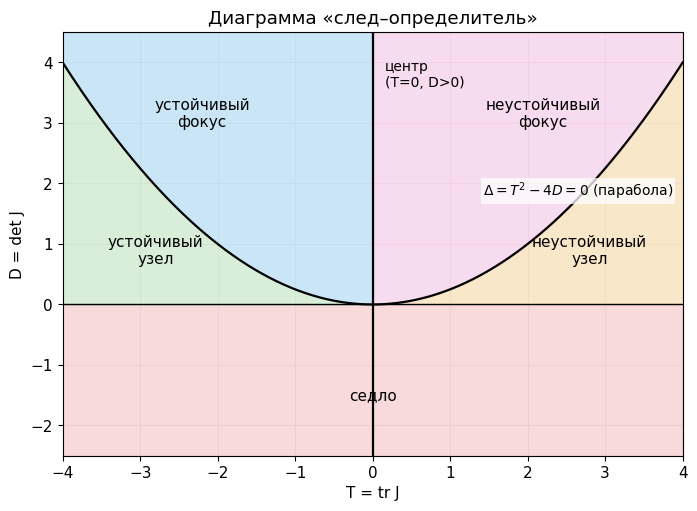

In [3]:
def td_diagram(ax=None, xlim=(-4, 4), ylim=(-2.5, 4.5), show_delta_label=True, saddle_pos=None):
    """Диаграмма след (T) - определитель (D): области типов особых точек."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5.5))
    T = np.linspace(*xlim, 600)
    ax.fill_between(T, ylim[0], 0, color='#f4b6b6', alpha=.5)                  # седло
    ax.fill_between(T, 0, T**2/4, where=T < 0, color='#bfe3bf', alpha=.6)      # устойчивый узел
    ax.fill_between(T, 0, T**2/4, where=T > 0, color='#f6d8a8', alpha=.6)      # неустойчивый узел
    ax.fill_between(T, T**2/4, ylim[1], where=T < 0, color='#a8d5f0', alpha=.6)  # устойчивый фокус
    ax.fill_between(T, T**2/4, ylim[1], where=T > 0, color='#f3c4e3', alpha=.6)  # неустойчивый фокус
    ax.plot(T, T**2/4, 'k', lw=1.6)
    ax.axhline(0, color='k', lw=1); ax.axvline(0, color='k', lw=1.6)
    xs_, xu_ = xlim[0]*0.7, xlim[1]*0.7          # где подписывать узлы: под параболой
    sp_ = saddle_pos if saddle_pos is not None else (0.0*xlim[1], ylim[0]*0.6)
    for xy, s in [(sp_, 'седло'),
                  ((xs_, 0.45*xs_**2/4), 'устойчивый\nузел'),
                  ((xu_, 0.45*xu_**2/4), 'неустойчивый\nузел'),
                  ((xlim[0]*0.55, ylim[1]*0.7), 'устойчивый\nфокус'),
                  ((xlim[1]*0.55, ylim[1]*0.7), 'неустойчивый\nфокус')]:
        ax.text(*xy, s, ha='center', va='center', fontsize=11)
    ax.text(0.04*xlim[1], ylim[1]*0.9, 'центр\n(T=0, D>0)', fontsize=10, va='top')
    if show_delta_label:
        xr = 0.97*xlim[1]
        ax.text(xr, 0.5*xr**2/4, r'$\Delta=T^2-4D=0$ (парабола)', fontsize=10, ha='right', va='center',
                bbox=dict(facecolor='white', alpha=.75, edgecolor='none', pad=1.5))
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel('T = tr J'); ax.set_ylabel('D = det J')
    ax.set_title('Диаграмма «след–определитель»')
    return ax

td_diagram()
plt.show()

### 1.4. Устойчивость по Ляпунову

Положение равновесия **устойчиво по Ляпунову**, если малое начальное отклонение остаётся малым всегда: для любого допуска $\varepsilon>0$ найдётся стартовая окрестность $\delta_L>0$ (здесь она названа $\delta_L$, чтобы не путать с коэффициентом трения $\delta$), такая что решение, стартовавшее ближе $\delta_L$ к равновесию, остаётся ближе $\varepsilon$ при всех $t\ge 0$. Равновесие **асимптотически устойчиво**, если, кроме того, решение стремится к равновесию при $t\to\infty$.

Практические правила (теорема об устойчивости по первому приближению):

* все $\operatorname{Re}\lambda<0$ $\Rightarrow$ равновесие нелинейной системы асимптотически устойчиво;
* хотя бы один $\operatorname{Re}\lambda>0$ (в частности, седло) $\Rightarrow$ неустойчиво;
* $\operatorname{Re}\lambda=0$ (центр линеаризации) $\Rightarrow$ **линеаризация ответа не даёт**: нелинейные добавки могут сделать точку и устойчивой, и неустойчивой. Именно этот случай встречается у консервативных систем, и его разбирают через энергию (раздел 1.5).

### 1.5. Консервативные системы ($\delta=0$): энергия и потенциал

При $\delta=0$ уравнение имеет вид $\ddot x=-U'(x)$, где

$$U(x)=\omega^2\int_0^x g(s)\,ds$$

— **потенциальная функция** (потенциал). Для гармонического осциллятора $U=\omega^2x^2/2$, для маятника $U=\omega^2(1-\cos x)$.

**Первый интеграл (энергия).** Определим

$$E(x,v)=\frac{v^2}{2}+U(x).$$

Тогда вдоль решений

$$\dot E=v\,\dot v+U'(x)\,\dot x=v\,(-U'(x))+U'(x)\,v=0.$$

Энергия не меняется со временем, поэтому **траектория лежит на линии уровня $E(x,v)=\text{const}$**. Фазовый портрет консервативной системы — это просто карта линий уровня энергии. Из $E=\text{const}$ следует $v=\pm\sqrt{2(E-U(x))}$: движение возможно только там, где $U(x)\le E$, а точки поворота ($v=0$) находятся при $U(x)=E$.

**Связь потенциала с типом особой точки.** Особые точки это $U'(x^*)=0$, то есть экстремумы потенциала. В них $g'(x^*)\omega^2=U''(x^*)$, и при $\delta=0$ получаем $\lambda^2=-U''(x^*)$. Поэтому:

* $U''(x^*)>0$ (минимум потенциала, «яма») $\Rightarrow$ $\lambda=\pm i\sqrt{U''}$, **центр**; линии уровня — замкнутые кривые вокруг точки;
* $U''(x^*)<0$ (максимум потенциала, «горб») $\Rightarrow$ $\lambda=\pm\sqrt{-U''}$, **седло**.

**Устойчивость центра.** В минимуме потенциала функция $E$ имеет строгий минимум. Линии уровня вокруг него — замкнутые кривые, стягивающиеся к точке при $E\to E_{\min}$. Поэтому траектория, стартовавшая достаточно близко, остаётся внутри нужной линии уровня и не может уйти далеко: центр **устойчив по Ляпунову** (но не асимптотически, ведь $E$ не убывает).

**Направление движения.** Первое уравнение $\dot x=v$ говорит: при $v>0$ координата $x$ растёт (движение вправо), при $v<0$ убывает (влево). В верхней полуплоскости стрелки направлены вправо, в нижней влево, поэтому вращение вокруг центра идёт **по часовой стрелке**.

### 1.6. Диссипативные системы ($\delta>0$)

При наличии трения энергия убывает:

$$\dot E=v\,\dot v+U'(x)\,v=v(-2\delta v-U')+U'v=-2\delta\,v^2\le 0.$$

Энергия теряется (уходит в тепло), траектории пересекают линии уровня $E$ в сторону меньших значений. Второе следствие — **сжатие фазового объёма**. Для системы $\dot x=f$, $\dot v=h$ дивергенция $\operatorname{div}=\partial_x f+\partial_v h=0+(-2\delta)=-2\delta$ для любого $g(x)$. Тогда любая область фазовой плоскости при эволюции сжимается: $S(t)=S(0)\,e^{-2\delta t}$. При $\delta=0$ площадь сохраняется (теорема Лиувилля). Из постоянства знака $\operatorname{div}$ ещё следует отсутствие замкнутых траекторий (критерий Бендиксона).

### 1.7. Численные методы

Для построения решений используется `scipy.integrate.solve_ivp` с методом `DOP853` (метод Рунге–Кутты 8-го порядка) и малыми допусками `rtol=1e-10`, `atol=1e-12`. Качество решения контролируется сохранением энергии (для консервативных систем) и сравнением с точными формулами там, где они есть.

### Вспомогательные функции

Ячейка ниже задаёт правую часть системы, потенциал, энергию, интегратор и функции рисования. Каждая функция снабжена комментарием; в разделах 2–5 они только вызываются.

In [4]:
# ------------------------ модель ------------------------
def g_force(x, kind):
    """Возвращающая сила g(x): 'lin' -> x, 'sin' -> sin x."""
    return x if kind == 'lin' else np.sin(x)

def make_rhs(omega, delta, kind):
    """Правая часть системы x' = v, v' = -2*delta*v - omega^2 g(x)."""
    def rhs(t, s):
        x, v = s
        return [v, -2*delta*v - omega**2*g_force(x, kind)]
    return rhs

def potential(x, omega, kind):
    """Потенциал U(x): omega^2 x^2/2 или omega^2 (1 - cos x)."""
    return omega**2*x**2/2 if kind == 'lin' else omega**2*(1 - np.cos(x))

def energy(x, v, omega, kind):
    """Энергия E = v^2/2 + U(x)."""
    return v**2/2 + potential(x, omega, kind)

def integrate(omega, delta, kind, x0, v0, T, n=2000, **kw):
    """Численное решение на [0, T]; возвращает t, x, v."""
    t = np.linspace(0, T, n)
    sol = solve_ivp(make_rhs(omega, delta, kind), (0, T), [x0, v0], t_eval=t,
                    method='DOP853', rtol=1e-10, atol=1e-12, **kw)
    return sol.t, sol.y[0], sol.y[1]

# ------------------------ классификация ------------------------
def classify(T, D, tol=1e-9):
    """Тип особой точки по следу T и определителю D матрицы Якоби."""
    Delta = T*T - 4*D
    if D < -tol:
        return 'седло'
    if abs(D) <= tol:
        return 'вырожденная точка (нулевой корень)'
    if abs(T) <= tol:
        return 'центр'
    st = 'устойчивый' if T < 0 else 'неустойчивый'
    if abs(Delta) <= tol:
        return st + ' вырожденный узел'
    return st + (' узел' if Delta > 0 else ' фокус')

def fmt_lam(lam):
    return ',  '.join(f'{z.real:+.3f}{z.imag:+.3f}i' if abs(z.imag) > 1e-12 else f'{z.real:+.3f}' for z in lam)

def eq_table(omega, delta, kind):
    """Печатает собственные значения и тип особых точек для заданных параметров."""
    pts = [(0.0, 'x*=0')] if kind == 'lin' else [(0.0, 'x*=0 (чётное k*pi)'), (np.pi, 'x*=pi (нечётное k*pi)')]
    for xs, name in pts:
        gp = 1.0 if kind == 'lin' else np.cos(xs)
        J = np.array([[0.0, 1.0], [-omega**2*gp, -2*delta]])
        lam = np.linalg.eigvals(J)
        T, D = np.trace(J), np.linalg.det(J)
        print(f'omega={omega}, delta={delta}: {name:22s} lambda = {fmt_lam(lam):28s} T={T:+.2f}, D={D:+.2f}  ->  {classify(T, D)}')

# ------------------------ рисование ------------------------
def equilibria(kind, xlim):
    """Особые точки в окне xlim: список (x*, 'min'|'max') по типу экстремума потенциала."""
    if kind == 'lin':
        return [(0.0, 'min')]
    ks = range(int(np.ceil(xlim[0]/np.pi - 1e-9)), int(np.floor(xlim[1]/np.pi + 1e-9)) + 1)
    return [(k*np.pi, 'min' if k % 2 == 0 else 'max') for k in ks]

def mark_equilibria(ax, kind, delta, xlim):
    """Центр/устойчивая точка - кружок, седло - крест."""
    for xs, typ in equilibria(kind, xlim):
        if typ == 'max':
            ax.plot(xs, 0, 'X', color='crimson', ms=11, mec='k', zorder=6)
        else:
            ax.plot(xs, 0, 'o', color='tab:blue' if delta == 0 else 'tab:green', ms=9, mec='k', zorder=6)

def eq_legend(ax, kind, delta, loc='upper right'):
    h = [Line2D([], [], marker='o', ls='', color='tab:blue' if delta == 0 else 'tab:green', mec='k',
                label='центр' if delta == 0 else 'устойчивая точка')]
    if kind == 'sin':
        h.append(Line2D([], [], marker='X', ls='', color='crimson', mec='k', label='седло'))
    ax.legend(handles=h, loc=loc, fontsize=9)

def phase_background(ax, omega, delta, kind, xlim, vlim, levels=None, stream=True, density=1.2, cmap='viridis'):
    """Фазовый портрет: поле направлений (streamplot) и, при заданных levels, линии уровня энергии."""
    X, V = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*vlim, 300))
    W = -2*delta*V - omega**2*g_force(X, kind)
    if levels is not None:
        ax.contour(X, V, energy(X, V, omega, kind), levels=levels, cmap=cmap, linewidths=1.2)
    if stream:
        ax.streamplot(X, V, V, W, color='0.55', density=density, linewidth=0.7, arrowsize=1.2)
    ax.set_xlim(xlim); ax.set_ylim(vlim)
    ax.set_xlabel('x'); ax.set_ylabel('v = dx/dt')

def wrap_angle(x):
    """Свёртка угла в (-pi, pi] с разрывом линии на скачках (для рисования на цилиндре)."""
    xw = (x + np.pi) % (2*np.pi) - np.pi
    jump = np.abs(np.diff(xw)) > np.pi
    xw = xw.copy(); xw[1:][jump] = np.nan
    return xw

def dynamics_figure(omega, delta, kind, ics, T, n=3000, wrap=False, xlim=None, vlim=None,
                    envelope=None, title='', stream=True):
    """Три панели: x(t), v(t) и фазовая плоскость с траекториями и полем направлений."""
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
    cols = plt.cm.tab10(np.arange(len(ics)))
    trajs = []
    for (x0, v0), c in zip(ics, cols):
        t, x, v = integrate(omega, delta, kind, x0, v0, T, n)
        trajs.append((t, x, v, c, x0, v0))
        ax[0].plot(t, x, color=c, label=f'x0={x0:g}, v0={v0:g}')
        ax[1].plot(t, v, color=c)
    if envelope is not None:
        te = np.linspace(0, T, n)
        ax[0].plot(te, envelope(te), 'k--', lw=1, label='огибающая'); ax[0].plot(te, -envelope(te), 'k--', lw=1)
    ax[0].set_xlabel('t'); ax[0].set_ylabel('x(t)'); ax[0].legend(fontsize=8)
    ax[1].set_xlabel('t'); ax[1].set_ylabel('v(t) = dx/dt')
    allx = np.concatenate([tr[1] for tr in trajs]); allv = np.concatenate([tr[2] for tr in trajs])
    if wrap:
        xlim = (-np.pi, np.pi)
    if xlim is None:
        m = 0.12*(allx.max() - allx.min() + 1e-9); xlim = (allx.min() - m, allx.max() + m)
    if vlim is None:
        m = 0.12*(allv.max() - allv.min() + 1e-9); vlim = (allv.min() - m, allv.max() + m)
    phase_background(ax[2], omega, delta, kind, xlim, vlim, stream=stream)
    for t, x, v, c, x0, v0 in trajs:
        xp = wrap_angle(x) if wrap else x
        ax[2].plot(xp, v, color=c, lw=1.8)
        ax[2].plot(x0 if not wrap else wrap_angle(np.array([x0, x0]))[0], v0, 'o', color=c, mec='k', zorder=5)
    mark_equilibria(ax[2], kind, delta, xlim)
    ax[2].set_title('фазовая плоскость' + (' (цилиндр: x mod 2π)' if wrap else ''))
    if title:
        fig.suptitle(title, y=1.02, fontsize=13)
    fig.tight_layout()
    return fig, ax

def evolve_cloud(omega, delta, kind, pts, tgrid):
    """Эволюция набора точек (граница облака начальных условий). Возвращает массивы x[t,i], v[t,i]."""
    N = len(pts)
    def rhs(t, y):
        x, v = y[:N], y[N:]
        return np.concatenate([v, -2*delta*v - omega**2*g_force(x, kind)])
    y0 = np.concatenate([pts[:, 0], pts[:, 1]])
    sol = solve_ivp(rhs, (tgrid[0], tgrid[-1]), y0, t_eval=tgrid, method='DOP853', rtol=1e-11, atol=1e-13)
    return sol.y[:N].T, sol.y[N:].T

def polygon_area(x, v):
    """Площадь многоугольника по формуле Гаусса (шнурования)."""
    return 0.5*np.abs(np.sum(x*np.roll(v, -1) - np.roll(x, -1)*v))

def area_ratio(omega, delta, kind, center, radius, tgrid, N=600):
    """Отношение площади эволюционирующего облака к начальной."""
    th = np.linspace(0, 2*np.pi, N, endpoint=False)
    pts = np.column_stack([center[0] + radius*np.cos(th), center[1] + radius*np.sin(th)])
    X, V = evolve_cloud(omega, delta, kind, pts, tgrid)
    return np.array([polygon_area(X[i], V[i]) for i in range(len(tgrid))])/polygon_area(pts[:, 0], pts[:, 1])

def dist_to_equilibrium(omega, delta, kind, x_star, r0, T, n=1500, angle=0.7):
    """Расстояние до особой точки вдоль решения, стартующего на расстоянии r0 (иллюстрация устойчивости)."""
    t, x, v = integrate(omega, delta, kind, x_star + r0*np.cos(angle), r0*np.sin(angle), T, n)
    return t, np.hypot(x - x_star, v)

def time_marks(ax, omega, delta, kind, ic, tmarks, color='k'):
    """Рисует траекторию и отмечает на ней моменты времени (чтобы увидеть направление движения)."""
    T = max(tmarks)
    t, x, v = integrate(omega, delta, kind, ic[0], ic[1], T, 2000)
    ax.plot(x, v, color=color, lw=1.5)
    for tm in tmarks:
        i = np.argmin(abs(t - tm))
        ax.plot(x[i], v[i], 'o', color='crimson', mec='k', zorder=5)
        ax.annotate(f't={tm:g}', (x[i], v[i]), textcoords='offset points', xytext=(6, 5), fontsize=9)
print('Функции определены.')

Функции определены.

---
## 2. Гармонический осциллятор без трения: $\ddot x+\omega^2x=0$

**Шаг 0. Уравнение и система.** С $v=\dot x$:

$$\dot x=v,\qquad \dot v=-\omega^2x.$$

Это груз на пружине без трения: сила пропорциональна отклонению.

### 2.1. Особые точки (пункт 1 задания)

Решаем $v=0,\ -\omega^2x=0$ символьно.

In [5]:
x, v = sp.symbols('x v', real=True)
w, d = sp.symbols('omega delta', positive=True)

F = sp.Matrix([v, -w**2*x])                    # правая часть системы
sols = sp.solve(list(F), [x, v], dict=True)    # решение системы F = 0
for s in sols:
    display(Math(r'(x^*,v^*)=(' + sp.latex(s[x]) + r',\,' + sp.latex(s[v]) + r')'))

<IPython.core.display.Math object>

Единственная особая точка — начало координат $(0,0)$ при любом $\omega$.

### 2.2. Линеаризация и устойчивость (пункт 2 задания)

Система уже линейна, поэтому матрица Якоби совпадает с матрицей системы.

In [6]:
J = F.jacobian([x, v])
display(Math(r'J=' + sp.latex(J)))
display(Math(r'T=\operatorname{tr}J=' + sp.latex(J.trace()) + r',\qquad D=\det J=' + sp.latex(J.det())))
display(Math(r'\lambda_{1,2}=' + sp.latex(list(J.eigenvals().keys()))))
print()
for om in OMEGAS_FREE:
    eq_table(om, 0.0, 'lin')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


omega=1.0, delta=0.0: x*=0                   lambda = +0.000+1.000i,  -0.000-1.000i T=+0.00, D=+1.00  ->  центр
omega=2.0, delta=0.0: x*=0                   lambda = +0.000+2.000i,  -0.000-2.000i T=+0.00, D=+4.00  ->  центр
omega=3.0, delta=0.0: x*=0                   lambda = +0.000+3.000i,  -0.000-3.000i T=+0.00, D=+9.00  ->  центр


**Вывод.** $T=0$, $D=\omega^2>0$, корни $\lambda=\pm i\omega$ чисто мнимые: особая точка — **центр**. Траектории вблизи неё — замкнутые кривые (эллипсы), движение по ним периодическое с периодом $2\pi/\omega$.

**Устойчивость по Ляпунову.** Для центра $\operatorname{Re}\lambda=0$, но система линейная, поэтому можно рассуждать точно. Величина

$$N(t)=\sqrt{\omega^2x^2+v^2}$$

не меняется (это $\sqrt{2E}$, см. п. 2.3). Для евклидова расстояния $\sqrt{x^2+v^2}$ получаем оценку $\min(1,\omega)\sqrt{x^2+v^2}\le N\le \max(1,\omega)\sqrt{x^2+v^2}$, откуда

$$\sqrt{x(t)^2+v(t)^2}\le K\sqrt{x_0^2+v_0^2},\qquad K=\max\!\big(\omega,\ 1/\omega\big).$$

Значит, для любого допуска $\varepsilon$ подходит $\delta_L=\varepsilon/K$: **устойчиво по Ляпунову**. Асимптотической устойчивости нет: расстояние до точки не стремится к нулю (энергия постоянна). Проверим численно: расстояние до начала координат для трёх значений $\omega$ ограничено числом $K$ и никогда не затухает.

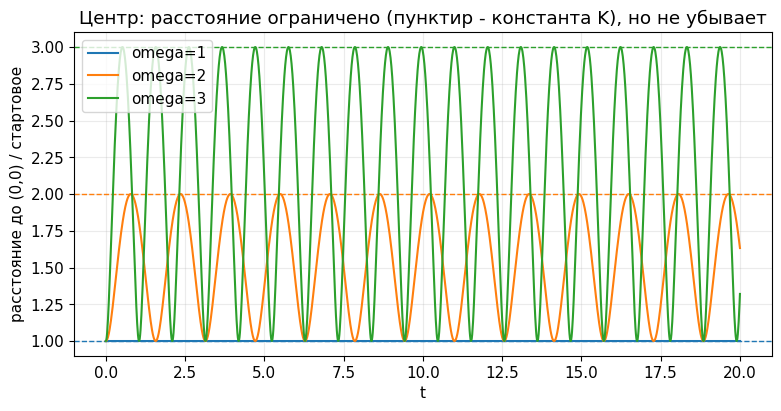

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for om, c in zip(OMEGAS_FREE, ['tab:blue', 'tab:orange', 'tab:green']):
    t, D = dist_to_equilibrium(om, 0.0, 'lin', 0.0, 0.05, 20, angle=0.0)
    ax.plot(t, D/0.05, color=c, label=f'omega={om:g}')
    K = max(om, 1/om)
    ax.axhline(K, color=c, ls='--', lw=1)
ax.set_xlabel('t'); ax.set_ylabel('расстояние до (0,0) / стартовое')
ax.set_title('Центр: расстояние ограничено (пунктир - константа K), но не убывает')
ax.legend(); plt.show()

### 2.3. Первый интеграл: энергия (пункт 3 задания)

Для $\ddot x=-\omega^2x$ потенциал $U(x)=\omega^2x^2/2$, энергия

$$E(x,v)=\frac{v^2}{2}+\frac{\omega^2x^2}{2}.$$

Проверим, что $\dot E=0$ вдоль решений.

In [8]:
E = (v**2 + w**2*x**2)/2
Edot = sp.diff(E, x)*F[0] + sp.diff(E, v)*F[1]       # dE/dt = E_x * x' + E_v * v'
display(Math(r'E=' + sp.latex(E)))
display(Math(r'\dot E=\frac{\partial E}{\partial x}\dot x+\frac{\partial E}{\partial v}\dot v=' + sp.latex(sp.simplify(Edot))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

$\dot E=0$: энергия — первый интеграл. Линия уровня $E=\text{const}$ это эллипс

$$\frac{x^2}{2E/\omega^2}+\frac{v^2}{2E}=1,$$

с полуосями $\sqrt{2E}/\omega$ по $x$ и $\sqrt{2E}$ по $v$. При $\omega=1$ эллипсы превращаются в окружности.

### 2.4. 3D-поверхность энергии, фазовый портрет и направление движения

Энергия — функция двух переменных, её график $z=E(x,v)$ — **параболоид** («чаша»), у которого минимум находится в центре. Линии уровня параболоида, спроецированные на плоскость $(x,v)$, и есть фазовый портрет.

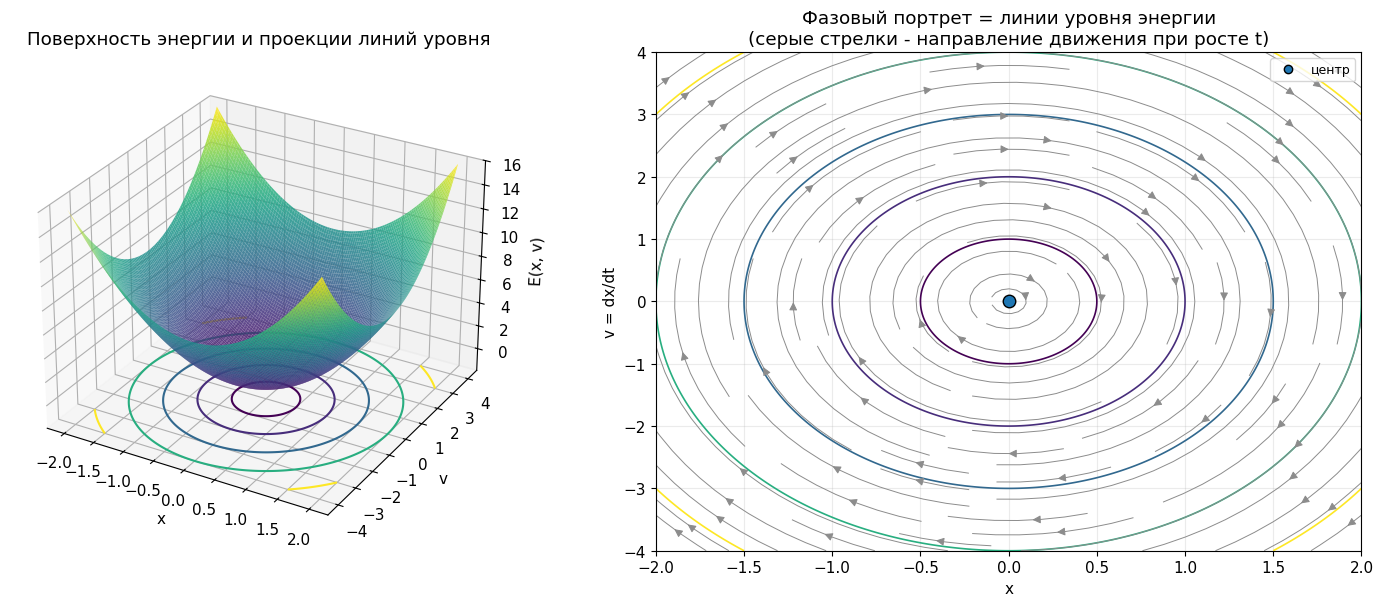

In [9]:
def energy_surface_and_portrait(omega, kind, xlim, vlim, levels, elev=28, azim=-60):
    fig = plt.figure(figsize=(15, 6.2))
    ax3 = fig.add_subplot(1, 2, 1, projection='3d')
    XX, VV = np.meshgrid(np.linspace(*xlim, 220), np.linspace(*vlim, 220))
    EE = energy(XX, VV, omega, kind)
    zbot = -0.12*EE.max()
    ax3.plot_surface(XX, VV, EE, cmap='viridis', alpha=0.85, linewidth=0, rstride=2, cstride=2)
    ax3.contour(XX, VV, EE, levels=levels, zdir='z', offset=zbot, cmap='viridis')
    ax3.set_zlim(zbot, EE.max())
    ax3.set_xlabel('x'); ax3.set_ylabel('v'); ax3.set_zlabel('E(x, v)')
    ax3.set_title('Поверхность энергии и проекции линий уровня')
    ax3.view_init(elev=elev, azim=azim)
    ax = fig.add_subplot(1, 2, 2)
    phase_background(ax, omega, 0.0, kind, xlim, vlim, levels=levels, stream=True, density=1.0)
    mark_equilibria(ax, kind, 0.0, xlim)
    eq_legend(ax, kind, 0.0)
    ax.set_title('Фазовый портрет = линии уровня энергии\n(серые стрелки - направление движения при росте t)')
    fig.tight_layout()
    return fig

om = 2.0
energy_surface_and_portrait(om, 'lin', (-2, 2), (-2*om, 2*om), levels=[0.5, 2, 4.5, 8, 12.5])
plt.show()

**Направление движения (пункт 3).** По уравнению $\dot x=v$ в верхней полуплоскости ($v>0$) координата $x$ растёт, то есть точка движется **вправо**, в нижней — **влево**. Значит, вокруг центра движение идёт **по часовой стрелке**. Убедимся на конкретной траектории, отметив на ней моменты времени.

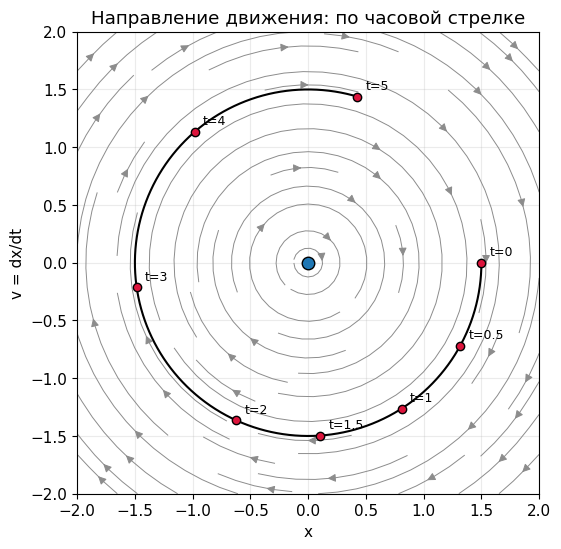

In [10]:
fig, ax = plt.subplots(figsize=(6.2, 6))
om = 1.0
phase_background(ax, om, 0.0, 'lin', (-2, 2), (-2, 2), stream=True, density=0.8)
time_marks(ax, om, 0.0, 'lin', (1.5, 0.0), [0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0])
mark_equilibria(ax, 'lin', 0.0, (-2, 2))
ax.set_aspect('equal'); ax.set_title('Направление движения: по часовой стрелке')
plt.show()

### 2.5. Потенциал и фазовый портрет (пункт 4 задания)

$U(x)=\omega^2x^2/2$ — парабола с единственным минимумом в $x=0$. На рисунке: сверху потенциал с горизонтальными линиями энергии $E$, снизу фазовый портрет с теми же значениями $E$ (тот же цвет). Точки пересечения линии $E$ с потенциалом — **точки поворота**: там $v=0$, и фазовая кривая пересекает ось $x$.

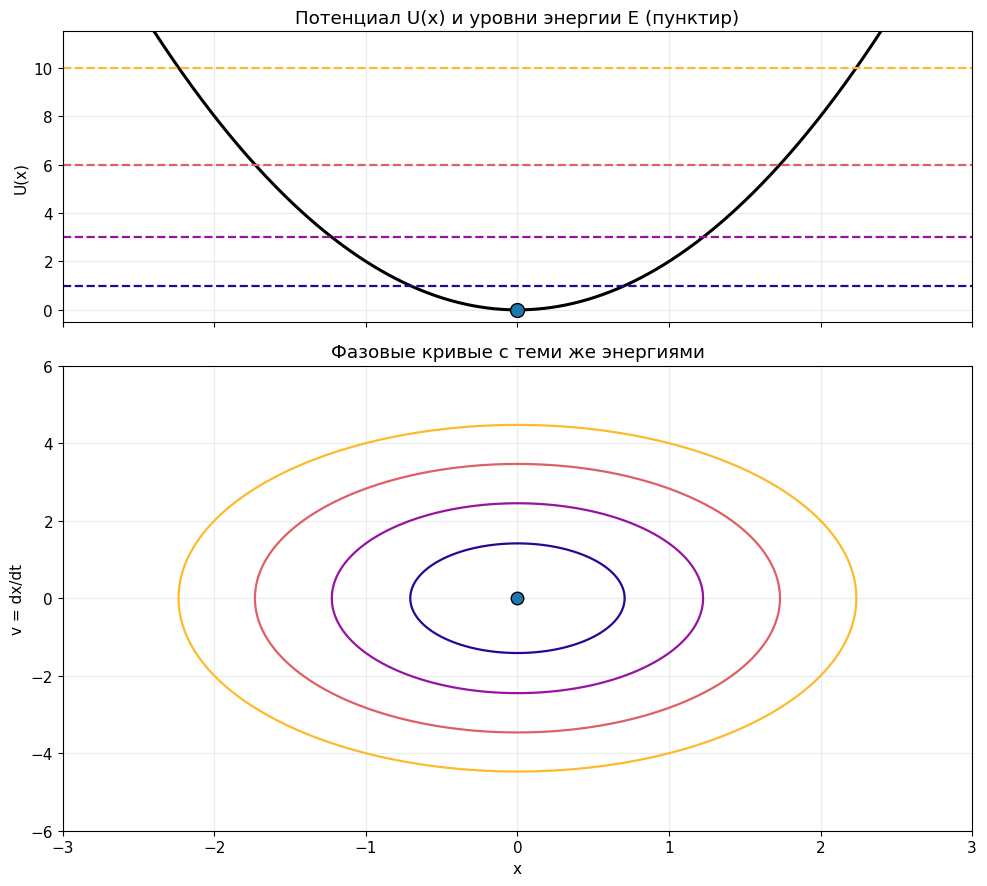

In [11]:
def potential_and_phase(omega, kind, xlim, vlim, energies, sep_energy=None):
    fig, (axU, axP) = plt.subplots(2, 1, figsize=(10, 9), sharex=True, gridspec_kw={'height_ratios': [1, 1.6]})
    xs = np.linspace(*xlim, 2000)
    axU.plot(xs, potential(xs, omega, kind), 'k', lw=2.2)
    cols = plt.cm.plasma(np.linspace(0.05, 0.85, len(energies)))
    X, V = np.meshgrid(np.linspace(*xlim, 800), np.linspace(*vlim, 600))
    Eg = energy(X, V, omega, kind)
    for En, c in zip(energies, cols):
        lw = 2.8 if (sep_energy is not None and abs(En - sep_energy) < 1e-9) else 1.6
        axU.axhline(En, color=c, ls='--', lw=lw)
        axP.contour(X, V, Eg, levels=[En], colors=[c], linewidths=lw)
    for xs_, typ in equilibria(kind, xlim):
        axU.plot(xs_, potential(xs_, omega, kind), 'o' if typ == 'min' else 'X',
                 color='tab:blue' if typ == 'min' else 'crimson', ms=10, mec='k', zorder=5)
    mark_equilibria(axP, kind, 0.0, xlim)
    axU.set_ylabel('U(x)'); axU.set_title('Потенциал U(x) и уровни энергии E (пунктир)')
    axU.set_ylim(-0.05*max(energies), 1.15*max(energies))
    axP.set_xlabel('x'); axP.set_ylabel('v = dx/dt'); axP.set_xlim(xlim); axP.set_ylim(vlim)
    axP.set_title('Фазовые кривые с теми же энергиями')
    fig.tight_layout()
    return fig

potential_and_phase(2.0, 'lin', (-3, 3), (-6, 6), energies=[1, 3, 6, 10])
plt.show()

**Связь потенциала и портрета.** Минимум потенциала ↔ центр. Чем выше энергия, тем шире яма «захватывает» движение и тем больше замкнутая кривая. У параболы нет других экстремумов, поэтому все траектории замкнуты и вращаются вокруг одной точки.

### 2.6. Решения и графики (пункты 5 и 6 задания)

Для гармонического осциллятора есть точное решение

$$x(t)=x_0\cos\omega t+\frac{v_0}{\omega}\sin\omega t,\qquad v(t)=-x_0\omega\sin\omega t+v_0\cos\omega t.$$

Сравним его с численным решением (проверка и интегратора, и формулы).

In [12]:
om, x0, v0 = 2.0, 1.0, 0.5
t, xn, vn = integrate(om, 0.0, 'lin', x0, v0, 15, 4000)
xe = x0*np.cos(om*t) + v0/om*np.sin(om*t)
ve = -x0*om*np.sin(om*t) + v0*np.cos(om*t)
print(f'максимальная разница |x_числ - x_точн| = {np.abs(xn - xe).max():.2e},  |v_числ - v_точн| = {np.abs(vn - ve).max():.2e}')
print(f'сохранение энергии: max|E(t)-E(0)| = {np.abs(energy(xn, vn, om, "lin") - energy(x0, v0, om, "lin")).max():.2e}')

максимальная разница |x_числ - x_точн| = 2.64e-10,  |v_числ - v_точн| = 5.53e-10
сохранение энергии: max|E(t)-E(0)| = 9.04e-10


Теперь для трёх значений $\omega$ и трёх разных начальных условий: слева $x(t)$, в центре $\dot x(t)$, справа контуры на фазовой плоскости. Заметьте, как $\omega$ влияет на **период** ($2\pi/\omega$) и на **форму** эллипсов (по $v$ они вытянуты в $\omega$ раз сильнее, чем по $x$).

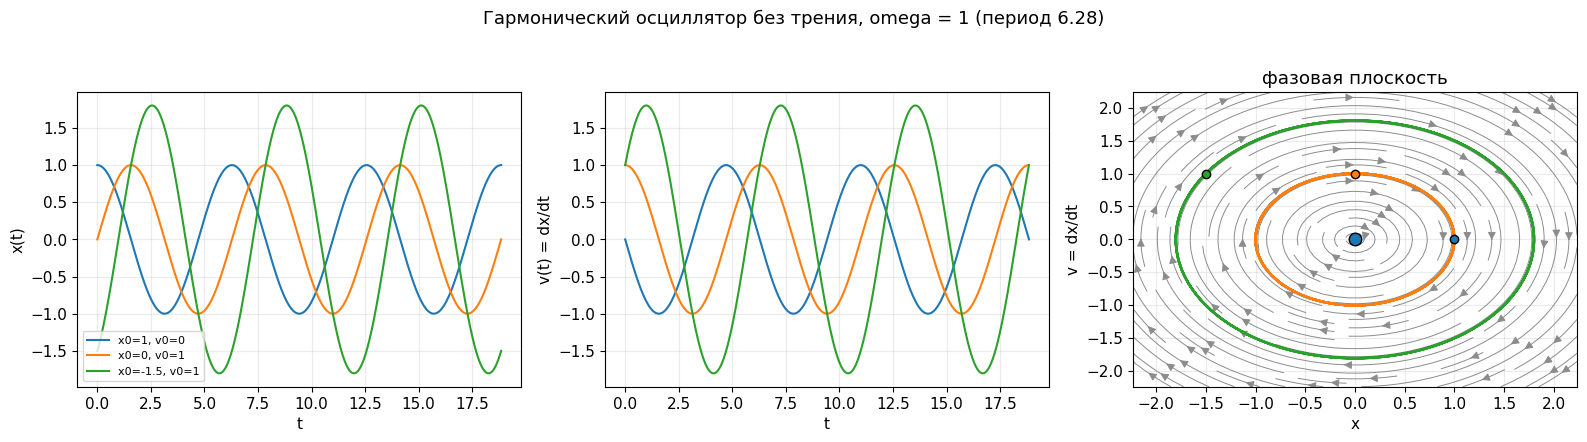

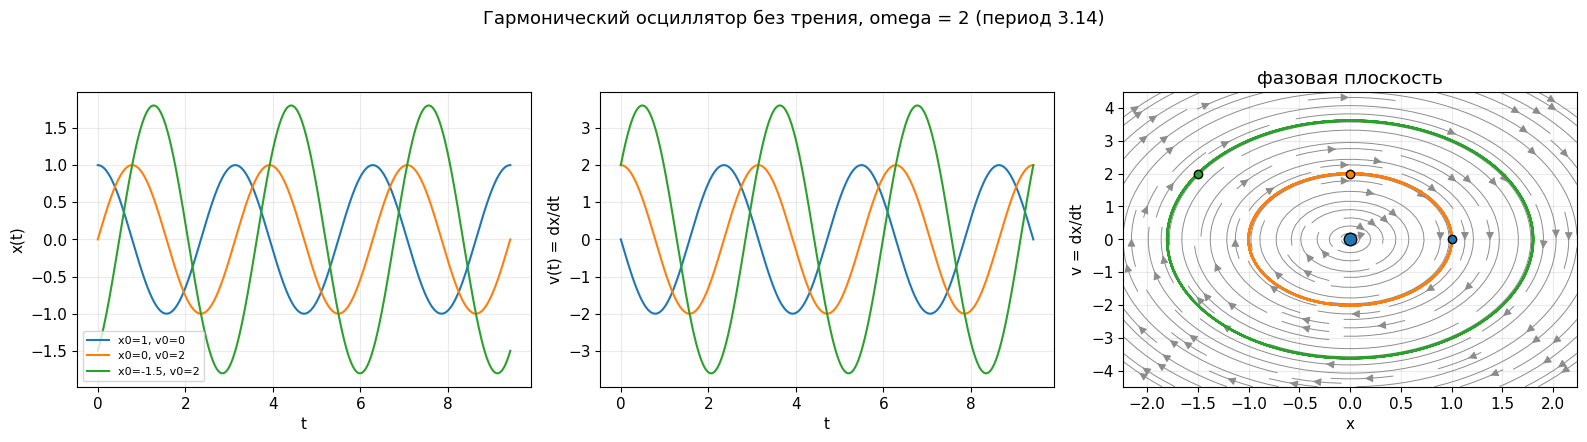

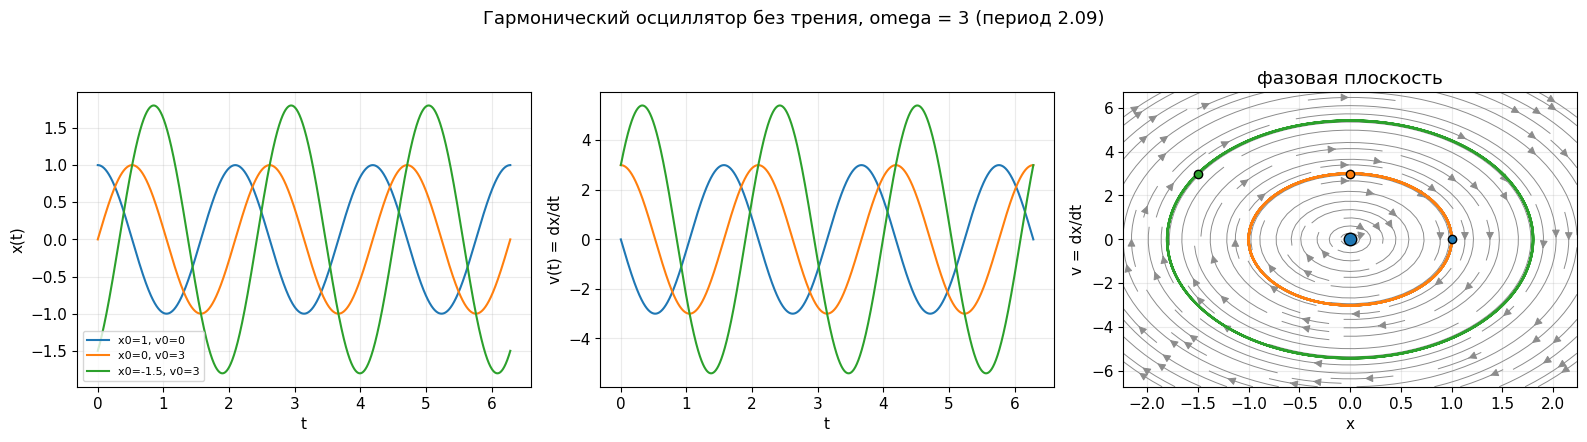

In [13]:
for om in OMEGAS_FREE:
    ics = [(1.0, 0.0), (0.0, 1.0*om), (-1.5, 1.0*om)]
    fig, ax = dynamics_figure(om, 0.0, 'lin', ics, T=4*np.pi/om*1.5, title=f'Гармонический осциллятор без трения, omega = {om:g} (период {2*np.pi/om:.2f})')
    plt.show()

### 2.7. Выводы по разделу

* Особая точка одна — **центр**; все траектории замкнуты (эллипсы энергии), вращение по часовой стрелке.
* Центр **устойчив по Ляпунову** и **не асимптотически** устойчив: возмущение не растёт, но и не затухает.
* Период колебаний $2\pi/\omega$ **не зависит от амплитуды** (изохронность). Это свойство именно гармонического осциллятора; ниже у маятника оно нарушится.
* Энергия сохраняется, фазовый объём сохраняется.

---
## 3. Гармонический осциллятор с трением: $\ddot x+2\delta\dot x+\omega^2x=0$

**Шаг 0. Система.**

$$\dot x=v,\qquad \dot v=-2\delta v-\omega^2x.$$

Для этой системы мы не вводим «потенциальный» вид (трение — не потенциальная сила), поэтому пункты 3–4 о первом интеграле и потенциале для неё не применяются (они относятся к консервативным системам). Вместо них разберём, как убывает энергия.

### 3.1. Особые точки и линеаризация (пункты 1–2 задания)

In [14]:
F = sp.Matrix([v, -2*d*v - w**2*x])
sols = sp.solve(list(F), [x, v], dict=True)
for s in sols:
    display(Math(r'(x^*,v^*)=(' + sp.latex(s[x]) + r',\,' + sp.latex(s[v]) + r')'))
J = F.jacobian([x, v])
Tsym, Dsym = J.trace(), J.det()
display(Math(r'J=' + sp.latex(J)))
display(Math(r'T=' + sp.latex(Tsym) + r',\quad D=' + sp.latex(Dsym) + r',\quad \Delta=T^2-4D=' + sp.latex(sp.factor(Tsym**2 - 4*Dsym))))
display(Math(r'\lambda_{1,2}=' + sp.latex(list(J.eigenvals().keys()))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Особая точка по-прежнему одна, $(0,0)$. Собственные значения $\lambda=-\delta\pm\sqrt{\delta^2-\omega^2}$. Здесь $T=-2\delta<0$, $D=\omega^2>0$, поэтому тип определяется знаком дискриминанта $\Delta=4(\delta^2-\omega^2)$, то есть сравнением трения с частотой:

| Соотношение | Корни | Тип точки | Движение |
|---|---|---|---|
| $\delta<\omega$ | комплексные, $\operatorname{Re}\lambda=-\delta$ | устойчивый **фокус** | затухающие колебания |
| $\delta=\omega$ | кратный $\lambda=-\delta$ | устойчивый **вырожденный узел** | критическое затухание: самое быстрое возвращение без колебаний |
| $\delta>\omega$ | вещественные, оба $<0$ | устойчивый **узел** | апериодическое затухание (колебаний нет) |

При всех $\delta>0$ имеем $\operatorname{Re}\lambda<0$, значит, нулевое положение равновесия **асимптотически устойчиво** (теорема о первом приближении; система линейна, поэтому вывод точный). Любое трение превращает центр в устойчивую точку.

In [15]:
for dl in DELTAS:
    eq_table(OMEGA_DAMP, dl, 'lin')

omega=2.0, delta=0.2: x*=0                   lambda = -0.200+1.990i,  -0.200-1.990i T=-0.40, D=+4.00  ->  устойчивый фокус
omega=2.0, delta=2.0: x*=0                   lambda = -2.000,  -2.000              T=-4.00, D=+4.00  ->  устойчивый вырожденный узел
omega=2.0, delta=4.0: x*=0                   lambda = -0.536,  -7.464              T=-8.00, D=+4.00  ->  устойчивый узел


### 3.2. Энергия как функция Ляпунова

Положим $E=(v^2+\omega^2x^2)/2$. Тогда $\dot E=-2\delta v^2$.

In [16]:
E = (v**2 + w**2*x**2)/2
Edot = sp.diff(E, x)*F[0] + sp.diff(E, v)*F[1]
display(Math(r'\dot E=' + sp.latex(sp.simplify(Edot))))

<IPython.core.display.Math object>

Так как $\dot E=-2\delta v^2\le 0$, энергия **не возрастает** (отсюда устойчивость по Ляпунову: расстояние в «энергетической норме» не увеличивается). Равенство $\dot E=0$ возможно лишь при $v=0$, но в точках $v=0$, $x\ne0$ ускорение $\dot v=-\omega^2x\ne0$, поэтому система не задерживается там, и энергия стремится к нулю. Это и есть асимптотическая устойчивость. Посмотрим на график $E(t)$ и проверим баланс $E(0)-E(T)=2\delta\int_0^Tv^2\,dt$.

delta=0.2: E(0)-E(T) = 1.984222,  2*delta*int v^2 dt = 1.984222
delta=2: E(0)-E(T) = 2.000000,  2*delta*int v^2 dt = 2.000000
delta=4: E(0)-E(T) = 1.999994,  2*delta*int v^2 dt = 1.999994


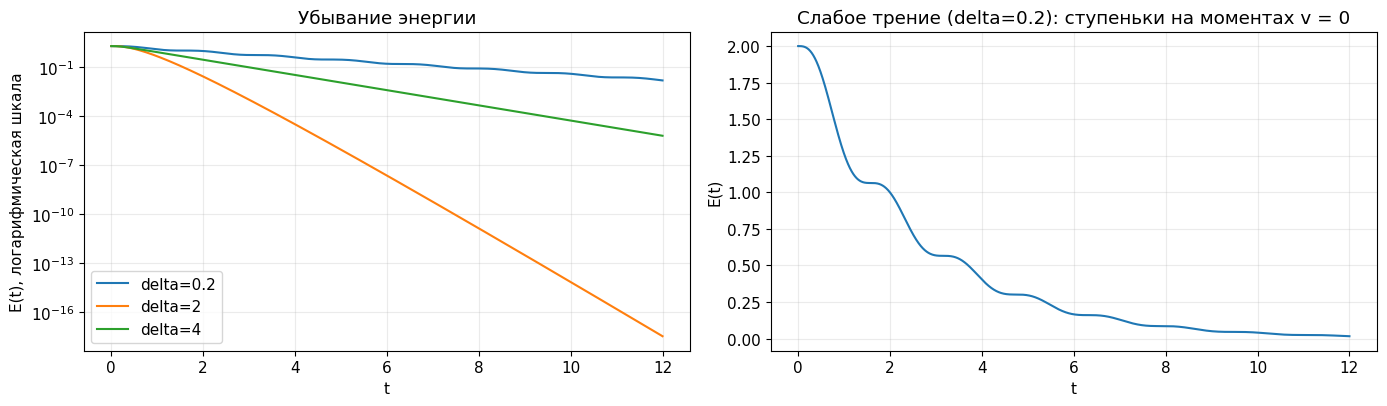

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for dl, c in zip(DELTAS, ['tab:blue', 'tab:orange', 'tab:green']):
    t, xx, vv = integrate(OMEGA_DAMP, dl, 'lin', 1.0, 0.0, 12, 3000)
    Et = energy(xx, vv, OMEGA_DAMP, 'lin')
    ax[0].semilogy(t, Et, color=c, label=f'delta={dl:g}')
    balance = Et[0] - Et[-1]; loss = 2*dl*np.trapezoid(vv**2, t)
    print(f'delta={dl:g}: E(0)-E(T) = {balance:.6f},  2*delta*int v^2 dt = {loss:.6f}')
ax[0].set_xlabel('t'); ax[0].set_ylabel('E(t), логарифмическая шкала'); ax[0].set_title('Убывание энергии'); ax[0].legend()
t, xx, vv = integrate(OMEGA_DAMP, DELTAS[0], 'lin', 1.0, 0.0, 12, 3000)
ax[1].plot(t, energy(xx, vv, OMEGA_DAMP, 'lin'), 'tab:blue')
ax[1].set_xlabel('t'); ax[1].set_ylabel('E(t)'); ax[1].set_title(f'Слабое трение (delta={DELTAS[0]:g}): ступеньки на моментах v = 0')
plt.tight_layout(); plt.show()

### 3.3. Фазовые портреты для трёх значений трения

Для $\delta\ge\omega$ (вещественные корни) на портрете показаны **собственные направления** — прямые $v=\lambda x$ (пунктир). Они указывают, вдоль каких прямых траектории входят в узел; вдали от начала траектории прижимаются к «медленному» направлению (корень с меньшим $|\lambda|$).

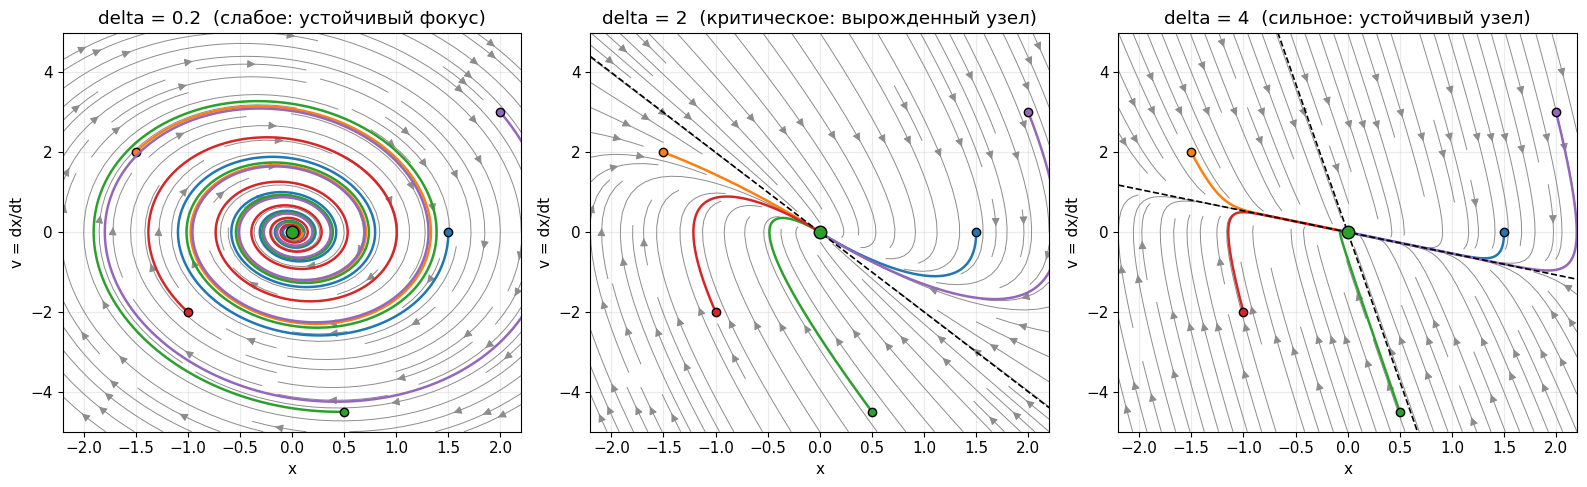

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
om = OMEGA_DAMP
xlim, vlim = (-2.2, 2.2), (-5, 5)
ics = [(1.5, 0.0), (-1.5, 2.0), (0.5, -4.5), (-1.0, -2.0), (2.0, 3.0)]
for ax, dl in zip(axes, DELTAS):
    phase_background(ax, om, dl, 'lin', xlim, vlim, stream=True, density=1.1)
    for (x0, v0), c in zip(ics, plt.cm.tab10(np.arange(len(ics)))):
        t, xx, vv = integrate(om, dl, 'lin', x0, v0, 15, 2500)
        ax.plot(xx, vv, color=c, lw=1.8); ax.plot(x0, v0, 'o', color=c, mec='k')
    if dl >= om - 1e-12:
        disc = np.sqrt(max(dl**2 - om**2, 0.0))
        for lam in sorted({-dl + disc, -dl - disc}):
            xs = np.array(xlim); ax.plot(xs, lam*xs, 'k--', lw=1.2)
    mark_equilibria(ax, 'lin', dl, xlim)
    tp = 'слабое: устойчивый фокус' if dl < om else ('критическое: вырожденный узел' if abs(dl - om) < 1e-12 else 'сильное: устойчивый узел')
    ax.set_title(f'delta = {dl:g}  ({tp})')
plt.tight_layout(); plt.show()

### 3.4. Решения, графики $x(t)$, $\dot x(t)$ и контуры (пункты 5–6)

Точные формулы:

* $\delta<\omega$: $x(t)=e^{-\delta t}\big(x_0\cos\omega_dt+\frac{v_0+\delta x_0}{\omega_d}\sin\omega_dt\big)$, $\omega_d=\sqrt{\omega^2-\delta^2}$, огибающая $A\,e^{-\delta t}$, $A=\sqrt{x_0^2+\big(\frac{v_0+\delta x_0}{\omega_d}\big)^2}$;
* $\delta=\omega$: $x(t)=\big(x_0+(v_0+\delta x_0)t\big)e^{-\delta t}$;
* $\delta>\omega$: сумма двух убывающих экспонент (колебаний нет).

Ниже численные решения (они совпадают с формулами) для трёх начальных условий.

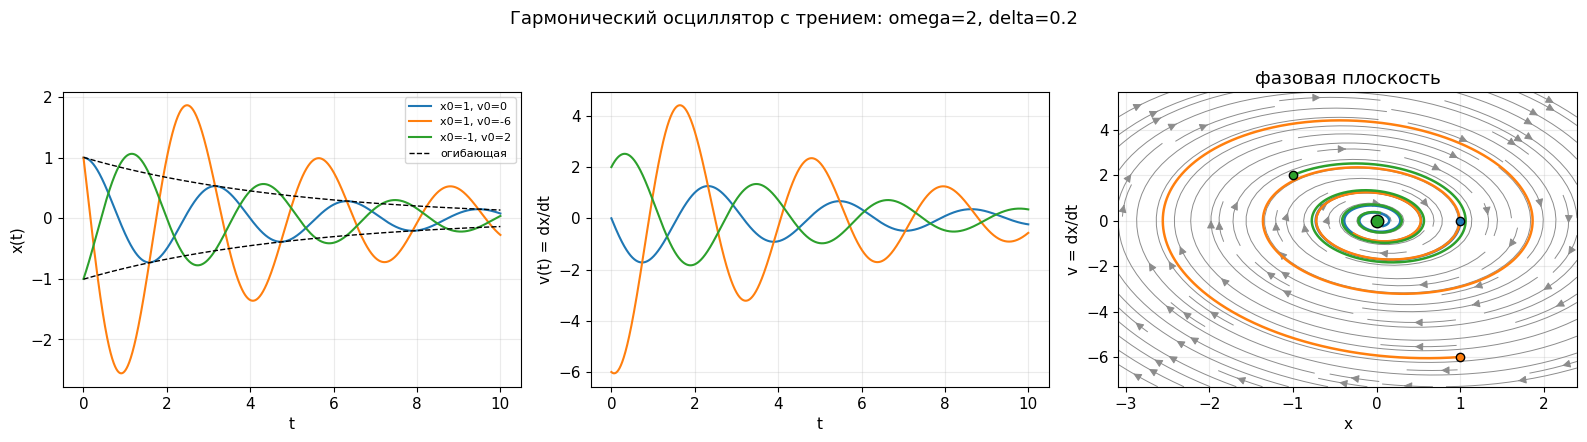

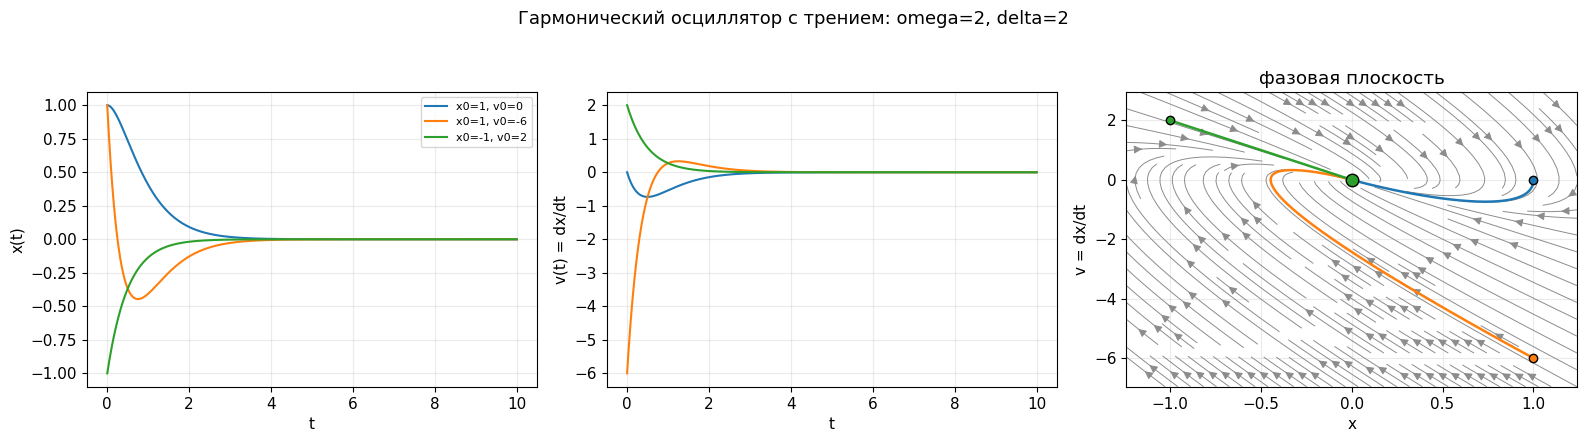

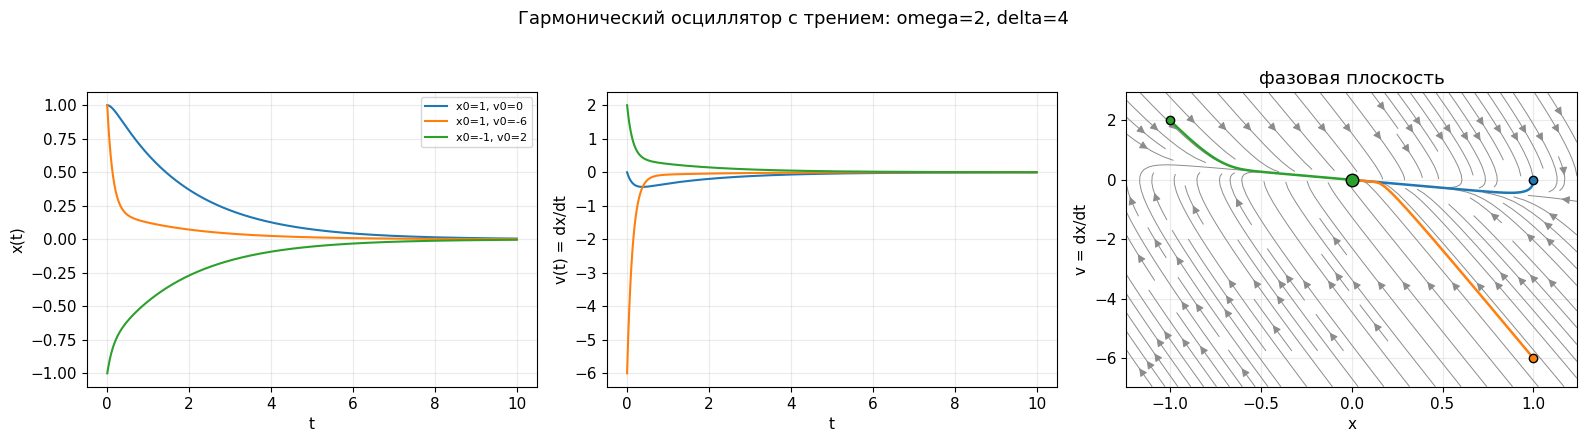

In [19]:
om = OMEGA_DAMP
for dl in DELTAS:
    ics = [(1.0, 0.0), (1.0, -6.0), (-1.0, 2.0)]
    env = None
    if dl < om:
        wd = np.sqrt(om**2 - dl**2); x0, v0 = ics[0]
        A = np.hypot(x0, (v0 + dl*x0)/wd)
        env = lambda tt, A=A, dl=dl: A*np.exp(-dl*tt)
    fig, ax = dynamics_figure(om, dl, 'lin', ics, T=10, envelope=env,
                              title=f'Гармонический осциллятор с трением: omega={om:g}, delta={dl:g}')
    plt.show()

Что видно на графиках:

* **$\delta=0{,}2<\omega$:** $x(t)$ — затухающая косинусоида внутри огибающей $\pm Ae^{-\delta t}$; на фазовой плоскости — спираль, закручивающаяся в нуль;
* **$\delta=\omega$:** колебаний нет, решение подходит к нулю быстрее всего;
* **$\delta>\omega$:** решение подходит к нулю монотонно; кривая $x(t)$ пересекает ось времени **не более одного раза** (в примере с $v_0=-6$ — ровно один раз).

**Проверка: логарифмический декремент.** Для слабого трения отношение последовательных максимумов $x(t)$ постоянно: $\ln\frac{x_n}{x_{n+1}}=\delta T_d$, где $T_d=2\pi/\omega_d$. Сверим с численным решением.

In [20]:
om, dl = OMEGA_DAMP, DELTAS[0]
t, xx, vv = integrate(om, dl, 'lin', 1.0, 0.0, 40, 40000)
pk, _ = find_peaks(xx)
ratio = np.log(xx[pk][:-1]/xx[pk][1:])
Td = 2*np.pi/np.sqrt(om**2 - dl**2)
print(f'период затухающих колебаний T_d = {Td:.4f};  по пикам: {np.mean(np.diff(t[pk])):.4f}')
print(f'логарифмический декремент: теория delta*T_d = {dl*Td:.4f},  численно = {ratio.mean():.4f}')

период затухающих колебаний T_d = 3.1574;  по пикам: 3.1574
логарифмический декремент: теория delta*T_d = 0.6315,  численно = 0.6315


### 3.5. Сжатие фазового объёма

Для линейной системы дивергенция $-2\delta$ постоянна, поэтому площадь любой области убывает строго как $e^{-2\delta t}$. Возьмём круг начальных условий и проследим за его площадью (граница эволюционирует по уравнениям системы, площадь считается по формуле Гаусса).

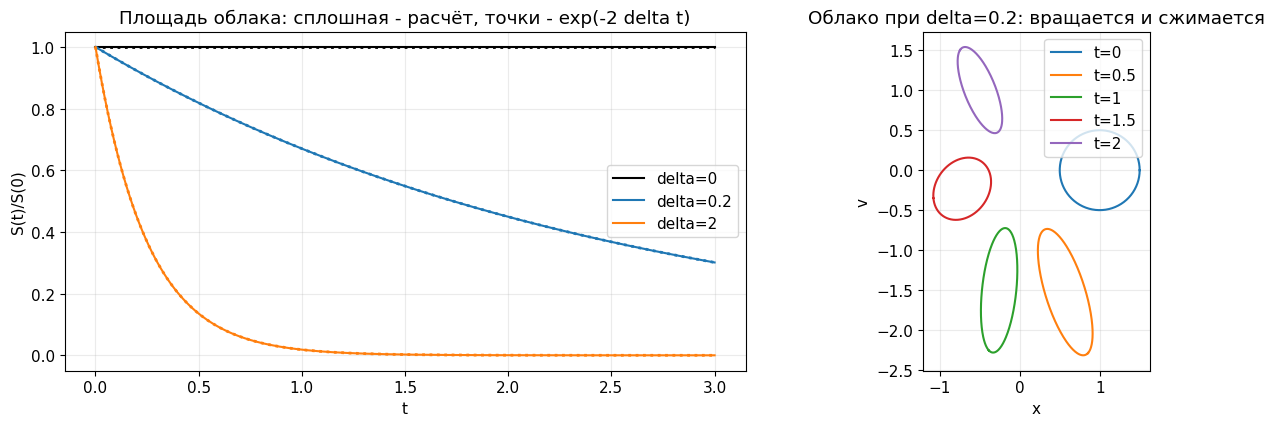

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
tg = np.linspace(0, 3, 200)
for dl, c in zip([0.0] + DELTAS[:2], ['k', 'tab:blue', 'tab:orange']):
    S = area_ratio(OMEGA_DAMP, dl, 'lin', (1.0, 0.0), 0.5, tg)
    ax[0].plot(tg, S, color=c, label=f'delta={dl:g}')
    ax[0].plot(tg, np.exp(-2*dl*tg), color=c, ls=':', lw=2)
ax[0].set_xlabel('t'); ax[0].set_ylabel('S(t)/S(0)'); ax[0].legend()
ax[0].set_title('Площадь облака: сплошная - расчёт, точки - exp(-2 delta t)')
# картинка облака в разные моменты (слабое трение)
th = np.linspace(0, 2*np.pi, 300, endpoint=False)
pts = np.column_stack([1.0 + 0.5*np.cos(th), 0.5*np.sin(th)])
tg2 = np.array([0, 0.5, 1.0, 1.5, 2.0])
X, V = evolve_cloud(OMEGA_DAMP, DELTAS[0], 'lin', pts, tg2)
for i, tt in enumerate(tg2):
    ax[1].plot(np.append(X[i], X[i][0]), np.append(V[i], V[i][0]), label=f't={tt:g}')
ax[1].set_xlabel('x'); ax[1].set_ylabel('v'); ax[1].legend(); ax[1].set_aspect('equal')
ax[1].set_title(f'Облако при delta={DELTAS[0]:g}: вращается и сжимается')
plt.tight_layout(); plt.show()

### 3.6. Выводы по разделу

* Любое трение ($\delta>0$) превращает центр в **асимптотически устойчивую** точку. Это структурная неустойчивость центра: он существует только при строгом отсутствии трения.
* Характер точки задаёт отношение $\delta/\omega$: фокус (колебательное затухание), вырожденный узел (критическое), узел (апериодическое).
* Энергия убывает со скоростью $-2\delta v^2$; фазовая площадь сжимается как $e^{-2\delta t}$; у системы единственный аттрактор — нуль.
* При $\delta>\omega$ колебаний нет, что видно по числу пересечений оси времени.

---
## 4. Ангармонический осциллятор без трения: маятник $\ddot x+\omega^2\sin x=0$

**Шаг 0. Система.**

$$\dot x=v,\qquad \dot v=-\omega^2\sin x.$$

Здесь $x$ — угол отклонения от нижнего положения. Правая часть нелинейна: сила пропорциональна $\sin x$, а не $x$. Это и делает осциллятор **ангармоническим**: при малых углах $\sin x\approx x$ получается гармонический осциллятор, а при больших поведение качественно другое.

### 4.1. Особые точки (пункт 1 задания)

In [22]:
F = sp.Matrix([v, -w**2*sp.sin(x)])
sols = sp.solve(list(F), [x, v], dict=True)
for s in sols:
    display(Math(r'(x^*,v^*)=(' + sp.latex(s[x]) + r',\,' + sp.latex(s[v]) + r')'))
display(Math(r'\text{общее решение: } x^*=k\pi,\ k\in\mathbb Z,\qquad v^*=0'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

`sympy` показывает главные решения $x^*=0$ и $x^*=\pi$; остальные получаются прибавлением $2\pi k$. Физически существуют два положения равновесия: **нижнее** ($x^*=2k\pi$) и **верхнее** ($x^*=(2k+1)\pi$).

### 4.2. Линеаризация и характер точек (пункт 2 задания)

In [23]:
J = F.jacobian([x, v])
display(Math(r'J(x,v)=' + sp.latex(J)))
for xs, name in [(0, r'x^*=2k\pi\ (\text{нижнее})'), (sp.pi, r'x^*=(2k+1)\pi\ (\text{верхнее})')]:
    Js = J.subs({x: xs, v: 0})
    display(Math(name + r':\quad J=' + sp.latex(Js) + r',\quad \lambda_{1,2}=' + sp.latex(list(Js.eigenvals().keys()))
                 + r',\quad D=' + sp.latex(Js.det())))
print()
for om in OMEGAS_PEND:
    eq_table(om, 0.0, 'sin')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


omega=1.0, delta=0.0: x*=0 (чётное k*pi)     lambda = +0.000+1.000i,  -0.000-1.000i T=+0.00, D=+1.00  ->  центр
omega=1.0, delta=0.0: x*=pi (нечётное k*pi)  lambda = +1.000,  -1.000              T=+0.00, D=-1.00  ->  седло
omega=2.0, delta=0.0: x*=0 (чётное k*pi)     lambda = +0.000+2.000i,  -0.000-2.000i T=+0.00, D=+4.00  ->  центр
omega=2.0, delta=0.0: x*=pi (нечётное k*pi)  lambda = +2.000,  -2.000              T=+0.00, D=-4.00  ->  седло


**Нижнее положение** ($\cos x^*=1$): $\lambda=\pm i\omega$, $D=\omega^2>0$, $T=0$ — **центр линеаризации**.

**Верхнее положение** ($\cos x^*=-1$): $\lambda=\pm\omega$, $D=-\omega^2<0$ — **седло**. По теореме о первом приближении седло неустойчиво.

**Важная оговорка.** Для нижнего положения $\operatorname{Re}\lambda=0$, а в этом случае линеаризация **не определяет** устойчивость нелинейной системы (нелинейность могла бы превратить центр в фокус). Здесь вывод даёт энергия: нижнее положение — **строгий минимум** потенциала (см. ниже), значит, линии уровня энергии вокруг него замкнуты и стягиваются к точке: центр **сохраняется** и **устойчив по Ляпунову** (не асимптотически).

**Численная иллюстрация.** Начнём движение на малом расстоянии $r_0$ от каждого положения равновесия и посмотрим, как меняется расстояние. Вблизи центра оно остаётся ограниченным, вблизи седла растёт экспоненциально со скоростью, близкой к $\omega$ (на полулогарифмическом графике это прямая с наклоном $\omega$ — собственное число $\lambda=+\omega$).

omega=1: наклон ln(расстояние) вблизи седла = 1.000  (теория: lambda=omega=1)
omega=2: наклон ln(расстояние) вблизи седла = 2.004  (теория: lambda=omega=2)


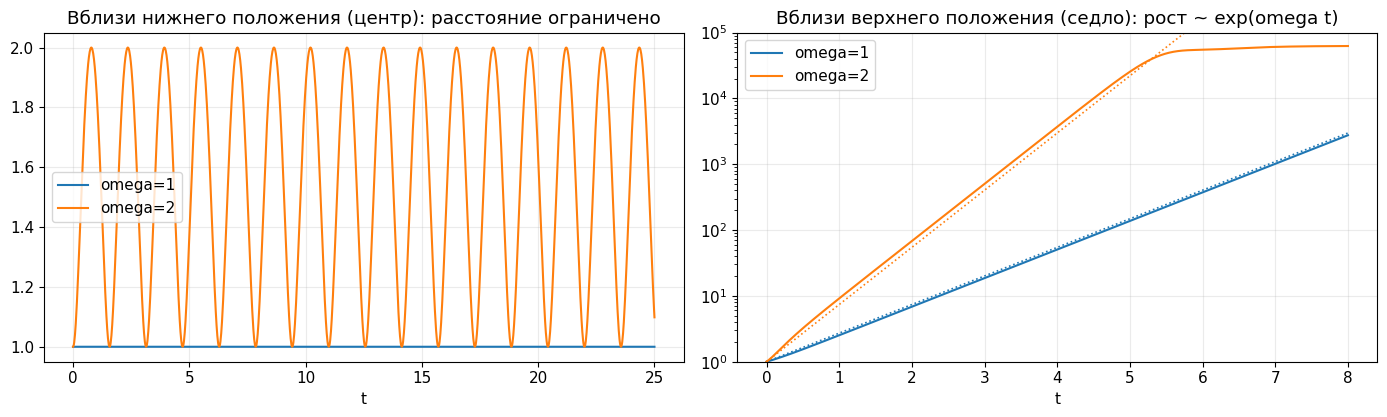

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
r0 = 1e-4
for om, c in zip(OMEGAS_PEND, ['tab:blue', 'tab:orange']):
    t, D = dist_to_equilibrium(om, 0.0, 'sin', 0.0, r0, 25, angle=0.0)
    ax[0].plot(t, D/r0, color=c, label=f'omega={om:g}')
    t, D = dist_to_equilibrium(om, 0.0, 'sin', np.pi, r0, 8, angle=0.4)
    ax[1].semilogy(t, D/r0, color=c, label=f'omega={om:g}')
    mask = (D/r0 > 5) & (D/r0 < 1e3)
    slope = np.polyfit(t[mask], np.log(D[mask]/r0), 1)[0]
    ax[1].semilogy(t, np.exp(om*t)*1.0, color=c, ls=':', lw=1.2)
    print(f'omega={om:g}: наклон ln(расстояние) вблизи седла = {slope:.3f}  (теория: lambda=omega={om:g})')
ax[0].set_title('Вблизи нижнего положения (центр): расстояние ограничено'); ax[0].set_xlabel('t'); ax[0].legend()
ax[1].set_title('Вблизи верхнего положения (седло): рост ~ exp(omega t)'); ax[1].set_xlabel('t'); ax[1].legend()
ax[1].set_ylim(1, 1e5)
plt.tight_layout(); plt.show()

### 4.3. Первый интеграл: энергия (пункт 3 задания)

Потенциал и энергия маятника:

$$U(x)=\omega^2\int_0^x\sin s\,ds=\omega^2(1-\cos x),\qquad E(x,v)=\frac{v^2}{2}+\omega^2(1-\cos x).$$

(Константа выбрана так, чтобы $U(0)=0$, то есть $E=0$ в нижнем положении покоя.) Проверим $\dot E=0$.

In [25]:
E = v**2/2 + w**2*(1 - sp.cos(x))
Edot = sp.diff(E, x)*F[0] + sp.diff(E, v)*F[1]
display(Math(r'E=' + sp.latex(E)))
display(Math(r'\dot E=' + sp.latex(sp.simplify(Edot))))
U = w**2*(1 - sp.cos(x))
display(Math(r"U'(x)=" + sp.latex(sp.diff(U, x)) + r",\qquad U''(x)=" + sp.latex(sp.diff(U, x, 2))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

$\dot E=0$ — энергия сохраняется. Вторая производная потенциала $U''(x)=\omega^2\cos x$ подтверждает связь с типом точек:

* $x^*=2k\pi$: $U''=\omega^2>0$, минимум потенциала — центр;
* $x^*=(2k+1)\pi$: $U''=-\omega^2<0$, максимум потенциала — седло.

### 4.4. Потенциал и фазовый портрет (пункт 4 задания)

Потенциал маятника — периодическая «волнистая» кривая с ямами в $x=2k\pi$ и горбами в $x=(2k+1)\pi$. Высота горба над дном ямы равна $U_{\max}=2\omega^2$. Это **пороговая энергия** $E_{\rm sep}=2\omega^2$, и она разделяет три типа движения:

| Энергия | Тип движения | Фазовая кривая |
|---|---|---|
| $E<2\omega^2$ | колебания (либрация) внутри одной ямы | замкнутая кривая вокруг центра |
| $E=2\omega^2$ | **сепаратриса**: движение по границе между режимами | кривая, входящая в седло и выходящая из седла (за бесконечное время) |
| $E>2\omega^2$ | **вращение**: энергии хватает, чтобы перейти через горб | незамкнутая кривая $v=\pm\sqrt{2(E-U(x))}$, не пересекающая ось $x$ |

Рисунок показывает потенциал сверху и соответствующие кривые энергии снизу (одинаковый цвет — одинаковое $E$). Толстая линия — сепаратриса.

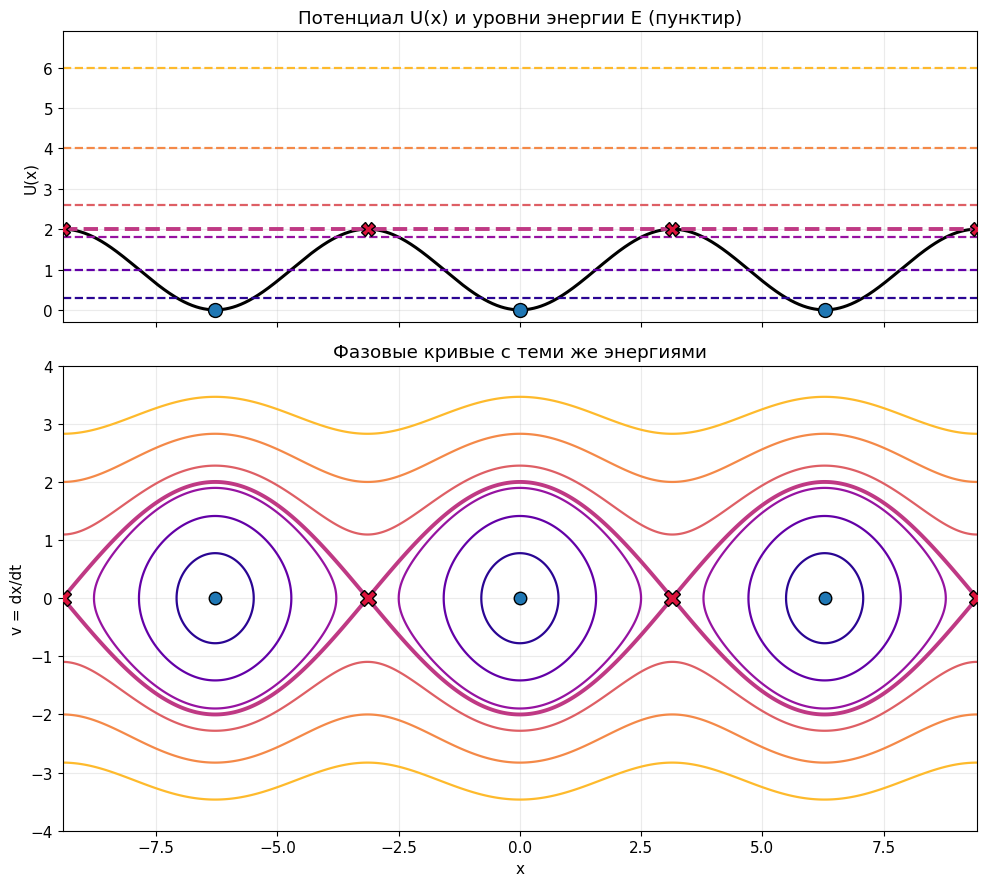

In [26]:
om = 1.0
Esep = 2*om**2
energies = [0.3, 1.0, 1.8, Esep, 2.6, 4.0, 6.0]
potential_and_phase(om, 'sin', (-3*np.pi, 3*np.pi), (-4, 4), energies, sep_energy=Esep)
plt.show()

**Что читать из рисунка.**

* Каждый **минимум** потенциала даёт **центр**: вокруг него замкнутые кривые малой энергии.
* Каждый **максимум** потенциала даёт **седло**; через седло проходит сепаратриса, отделяющая колебания от вращения.
* Для $E>E_{\rm sep}$ линия энергии лежит выше горбов; кривые на фазовой плоскости не замкнуты и идут через всю область: маятник вращается в одну сторону (при $v>0$ вправо, при $v<0$ влево).

### 4.5. 3D-поверхность энергии и фазовый портрет

Поверхность $z=E(x,v)=v^2/2+\omega^2(1-\cos x)$ — «волнистая чаша»: вдоль $v$ парабола, вдоль $x$ синусоидальный профиль. Ямы поверхности — центры, перевалы (седловины поверхности) — седла системы.

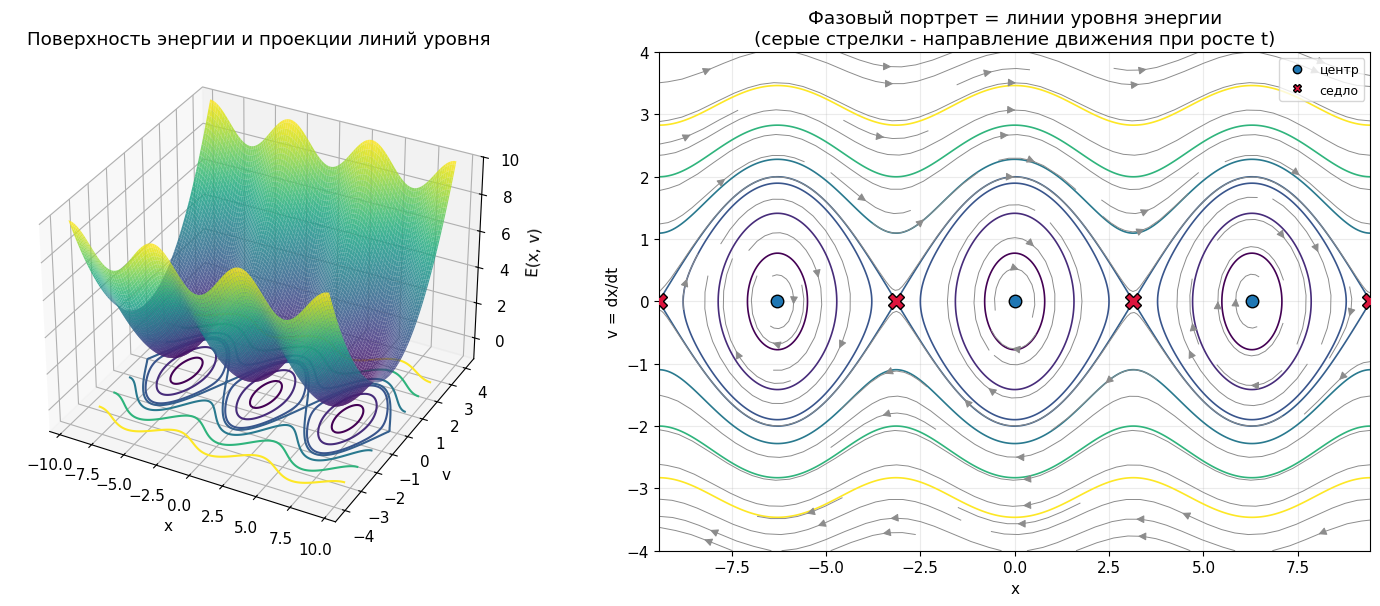

In [27]:
om = 1.0
energy_surface_and_portrait(om, 'sin', (-3*np.pi, 3*np.pi), (-4, 4),
                            levels=[0.3, 1.0, 1.8, 2.0, 2.6, 4.0, 6.0], elev=32, azim=-62)
plt.show()

### 4.6. Решения, существенно разные по характеру (пункты 5–6)

Выберем начальные условия $(x_0,v_0)$ с $\omega=1$ так, чтобы получить все типы движения. В третьей панели угол свёрнут по $2\pi$ (цилиндр), чтобы траектория вращения не уходила за пределы рисунка.

| Начальные условия | Энергия $E$ | Тип движения |
|---|---|---|
| $(0{,}3;\ 0)$ | $0{,}044$ | малые колебания (почти гармонические) |
| $(2{,}5;\ 0)$ | $1{,}80$ | большие колебания |
| $(0;\ 1{,}99)$ | $1{,}98$ | колебания у сепаратрисы (очень медленные у вершины) |
| $(0;\ 2{,}00)$ | $2{,}00$ | сепаратриса |
| $(0;\ 2{,}5)$ | $3{,}13$ | вращение |

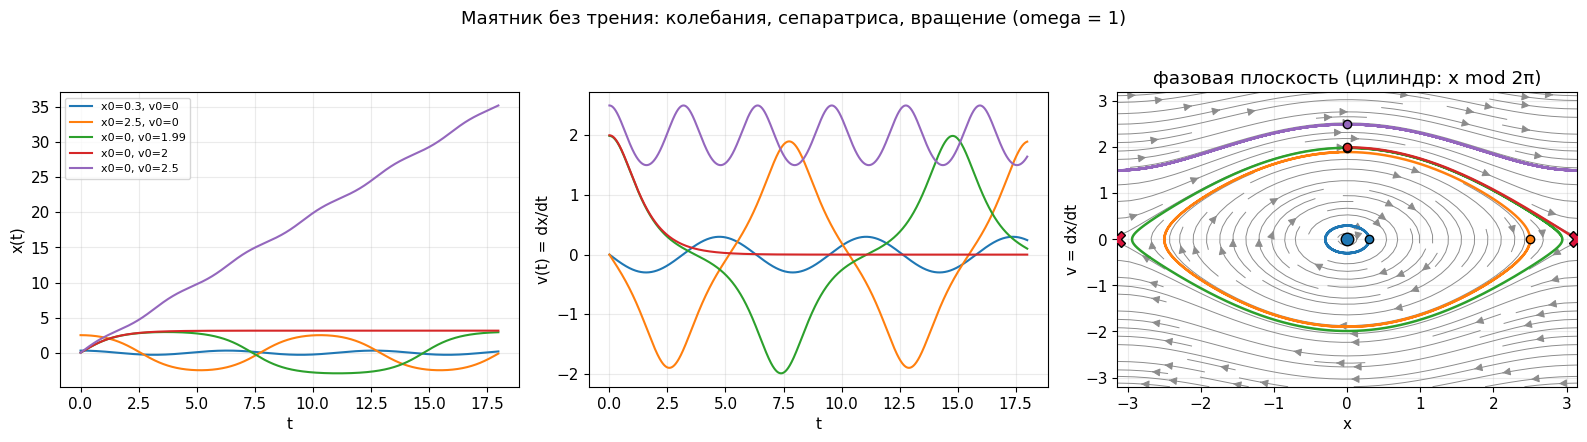

In [28]:
om = 1.0
ics_p = [(0.3, 0.0), (2.5, 0.0), (0.0, 1.99), (0.0, 2.0), (0.0, 2.5)]
fig, ax = dynamics_figure(om, 0.0, 'sin', ics_p, T=18, n=4000, wrap=True, vlim=(-3.2, 3.2),
                          title='Маятник без трения: колебания, сепаратриса, вращение (omega = 1)')
plt.show()

Что видно:

* малые колебания $x(t)$ почти синусоидальны, амплитуда 0,3;
* большие колебания уже заметно **несинусоидальны**: кривая $x(t)$ «сплющена» у вершин, потому что маятник дольше задерживается вблизи точек поворота;
* на сепаратрисе и вблизи неё (старт $v_0=1{,}99$) маятник долго «висит» около верхнего положения: на графике $x(t)$ видны плато около $\pm\pi$, а период колебаний у сепаратрисы растёт неограниченно;
* при вращении $x(t)$ монотонно растёт (угол накручивается), а $v(t)$ осциллирует вокруг среднего положительного значения; на фазовом цилиндре кривая не замкнута в смысле колебаний, она идёт вдоль окружности.

**Замечание о численной неустойчивости.** Траектория $(0;\,2)$ идёт точно по сепаратрисе: она подходит к верхнему положению $x=\pi$ и «зависает» там ($v\to0$, плато на графике $x(t)$). Но верхнее положение — седло, и любая численная ошибка растёт как $e^{\omega t}$ (при начальной ошибке порядка $10^{-10}$ она становится заметной уже при $t\approx25$). Поэтому на рисунке выбрано окно $T=18$: при большем $T$ численное решение сошло бы с сепаратрисы и «перескочило» через горб. Это не ошибка метода, а свойство самой задачи: траектории вблизи седла чувствительны к малым возмущениям.

**Точное решение для сепаратрисы.** Для $E=2\omega^2$ уравнение интегрируется в элементарных функциях:

$$x(t)=4\arctan\!\big(e^{\omega t}\big)-\pi,\qquad v(t)=\frac{2\omega}{\cosh\omega t}.$$

За бесконечное время $t\in(-\infty,\infty)$ угол меняется от $-\pi$ до $\pi$: маятник выходит из верхнего положения и приходит в верхнее же (с другой стороны). Проверим формулу и сохранение энергии.

E на сепаратрисе: min, max = 1.9999999999999991 2.000000000000001  (теория 2*omega^2 = 2.0 )
макс. разность численное - точное x(t) на [0, 8]: 1.464726118172166e-09


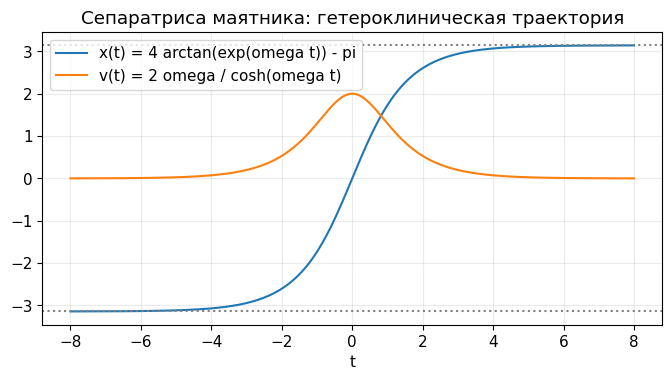

In [29]:
om = 1.0
t = np.linspace(-8, 8, 4001)
xs = 4*np.arctan(np.exp(om*t)) - np.pi
vs = 2*om/np.cosh(om*t)
print('E на сепаратрисе: min, max =', energy(xs, vs, om, 'sin').min(), energy(xs, vs, om, 'sin').max(), ' (теория 2*omega^2 =', 2*om**2, ')')
# сравнение с численным интегрированием из x(0)=0, v(0)=2 omega
tn, xn, vn = integrate(om, 0.0, 'sin', 0.0, 2*om, 8, 2001)
i = np.searchsorted(t, 0)
xe = 4*np.arctan(np.exp(om*tn)) - np.pi
print('макс. разность численное - точное x(t) на [0, 8]:', np.abs(xn - xe).max())
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(t, xs, label='x(t) = 4 arctan(exp(omega t)) - pi'); ax.plot(t, vs, label='v(t) = 2 omega / cosh(omega t)')
ax.axhline(np.pi, color='gray', ls=':'); ax.axhline(-np.pi, color='gray', ls=':')
ax.set_xlabel('t'); ax.set_title('Сепаратриса маятника: гетероклиническая траектория'); ax.legend(); plt.show()

### 4.7. Период зависит от амплитуды (неизохронность)

У гармонического осциллятора период $2\pi/\omega$ не зависит от амплитуды. У маятника это не так. Точная формула через полный эллиптический интеграл первого рода $K$ (модуль $k=\sin(\theta_0/2)$, где $\theta_0$ — амплитуда):

$$T(\theta_0)=\frac{4}{\omega}\,K\!\big(k\big),\qquad k=\sin\frac{\theta_0}{2}.$$

Приближённая формула (первая поправка, см. 4.8): $T\approx\frac{2\pi}{\omega}\big(1+\frac{\theta_0^2}{16}\big)$. Сверим точную формулу с численным определением периода (четверть периода — время от $\theta_0$ до первого прохождения $x=0$).

 theta0    T числ.   T точн. K(k)   T0(1+th^2/16)   T0=2pi/w
   0.10    6.28711        6.28711         6.28711    6.28319
   0.50    6.38279        6.38279         6.38136    6.28319
   1.00    6.69998        6.69998         6.67588    6.28319
   1.50    7.30086        7.30086         7.16676    6.28319
   2.00    8.34975        8.34975         7.85398    6.28319
   2.50   10.32316       10.32316         8.73755    6.28319
   3.00   16.15554       16.15554         9.81748    6.28319
   3.10   21.03922       21.03922        10.05702    6.28319


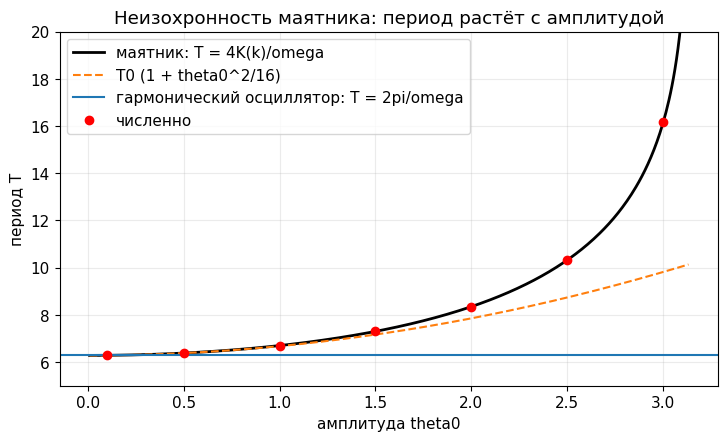

In [30]:
def quarter_period(theta0, omega):
    """Численно: время от (theta0, 0) до первого прохождения x = 0 (это четверть периода)."""
    ev = lambda t, s: s[0]
    ev.terminal = True; ev.direction = -1
    sol = solve_ivp(make_rhs(omega, 0.0, 'sin'), (0, 1e4), [theta0, 0.0], events=ev, rtol=1e-12, atol=1e-13)
    return sol.t_events[0][0]

om = 1.0
amps = np.array([0.1, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.1])
Tnum = np.array([4*quarter_period(a, om) for a in amps])
Texact = 4*ellipk(np.sin(amps/2)**2)/om           # scipy: ellipk(m), m = k^2
Tlin = 2*np.pi/om
Tapprox = Tlin*(1 + amps**2/16)
print(f'{"theta0":>7} {"T числ.":>10} {"T точн. K(k)":>14} {"T0(1+th^2/16)":>15} {"T0=2pi/w":>10}')
for a, tn_, te, ta in zip(amps, Tnum, Texact, Tapprox):
    print(f'{a:7.2f} {tn_:10.5f} {te:14.5f} {ta:15.5f} {Tlin:10.5f}')

aa = np.linspace(0.01, np.pi - 0.01, 400)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(aa, 4*ellipk(np.sin(aa/2)**2)/om, 'k', lw=2, label='маятник: T = 4K(k)/omega')
ax.plot(aa, Tlin*(1 + aa**2/16), 'tab:orange', ls='--', label='T0 (1 + theta0^2/16)')
ax.axhline(Tlin, color='tab:blue', label='гармонический осциллятор: T = 2pi/omega')
ax.plot(amps, Tnum, 'ro', label='численно')
ax.set_xlabel('амплитуда theta0'); ax.set_ylabel('период T'); ax.set_ylim(5, 20)
ax.set_title('Неизохронность маятника: период растёт с амплитудой'); ax.legend(); plt.show()

Период растёт с амплитудой и стремится к бесконечности при $\theta_0\to\pi$ (приближение к сепаратрисе: маятник бесконечно долго находится вблизи верхнего положения). Для малых амплитуд $T\to 2\pi/\omega$ — гармонический предел.

### 4.8. Приближённое аналитическое решение: метод Линштедта (оценка сдвига частоты)

Разложим $\sin x\approx x-x^3/6$ и подставим пробное решение $x=A\cos\Omega t$. Так как $\cos^3\tau=\frac{3\cos\tau+\cos3\tau}{4}$, коэффициент при первой гармонике должен обнуляться:

$$-\Omega^2A+\omega^2A-\frac{\omega^2}{6}\cdot\frac{3A^3}{4}=0\;\Rightarrow\;\Omega^2=\omega^2\Big(1-\frac{A^2}{8}\Big)\;\Rightarrow\;\Omega\approx\omega\Big(1-\frac{A^2}{16}\Big).$$

Частота **падает** с ростом амплитуды (маятник «мягкая» пружина). Сравним три решения при одном начальном условии: численное, линейное ($\cos\omega t$) и с поправкой Линштедта ($\cos\Omega t$).

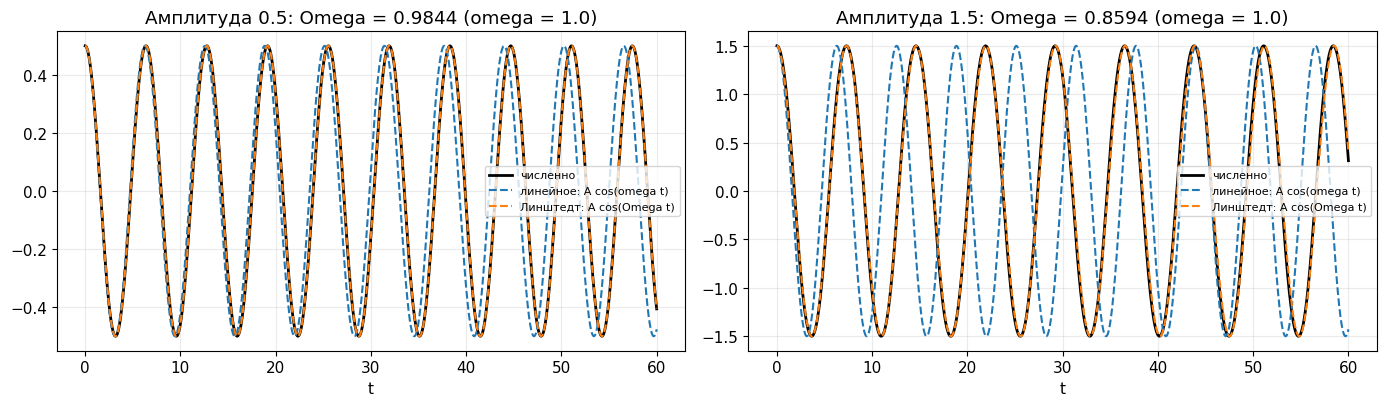

In [31]:
om = 1.0
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a_, A0 in zip(ax, [0.5, 1.5]):
    t, xn, vn = integrate(om, 0.0, 'sin', A0, 0.0, 60, 6000)
    Om = om*(1 - A0**2/16)
    a_.plot(t, xn, 'k', lw=2, label='численно')
    a_.plot(t, A0*np.cos(om*t), 'tab:blue', ls='--', label='линейное: A cos(omega t)')
    a_.plot(t, A0*np.cos(Om*t), 'tab:orange', ls='--', label='Линштедт: A cos(Omega t)')
    a_.set_title(f'Амплитуда {A0}: Omega = {Om:.4f} (omega = {om})'); a_.set_xlabel('t'); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

Линейное решение быстро «убегает» по фазе от точного, поправка Линштедта удерживает фазу намного дольше. Для малой амплитуды 0,5 оно практически неотличимо от численного решения на всём интервале; для 1,5 расхождение со временем накапливается (следующие порядки разложения дали бы более точный результат).

### 4.9. Выводы по разделу

* Особые точки $(k\pi,0)$: **центры** в нижних положениях, **седла** в верхних. Центры устойчивы по Ляпунову (не асимптотически), седла неустойчивы.
* Энергия $E=v^2/2+\omega^2(1-\cos x)$ сохраняется; **минимумы потенциала — центры, максимумы — седла**. Высота горба $2\omega^2$ задаёт сепаратрису: $E<2\omega^2$ колебания, $E>2\omega^2$ вращение.
* Нелинейность проявляется в **неизохронности**: период растёт с амплитудой и обращается в бесконечность на сепаратрисе. Гармонический осциллятор этого свойства не имеет.
* Фазовый объём сохраняется (теорема Лиувилля), система консервативна.

---
## 5. Ангармонический осциллятор с трением: $\ddot x+2\delta\dot x+\omega^2\sin x=0$

**Шаг 0. Система.**

$$\dot x=v,\qquad \dot v=-2\delta v-\omega^2\sin x.$$

### 5.1. Особые точки и линеаризация (пункты 1–2 задания)

Особые точки те же: $(k\pi,0)$ (при $v=0$ трения нет). Меняются собственные значения.

In [32]:
F = sp.Matrix([v, -2*d*v - w**2*sp.sin(x)])
sols = sp.solve(list(F), [x, v], dict=True)
for s in sols:
    display(Math(r'(x^*,v^*)=(' + sp.latex(s[x]) + r',\,' + sp.latex(s[v]) + r')'))
J = F.jacobian([x, v])
display(Math(r'J(x,v)=' + sp.latex(J)))
for xs, name in [(0, r'x^*=2k\pi\ (\text{нижнее})'), (sp.pi, r'x^*=(2k+1)\pi\ (\text{верхнее})')]:
    Js = J.subs({x: xs, v: 0})
    display(Math(name + r':\quad J=' + sp.latex(Js)))
    display(Math(r'\quad T=' + sp.latex(Js.trace()) + r',\ D=' + sp.latex(Js.det()) + r',\ \lambda_{1,2}=' + sp.latex(list(Js.eigenvals().keys()))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Нижнее положение** ($\cos x^*=1$): $\lambda=-\delta\pm\sqrt{\delta^2-\omega^2}$, $T=-2\delta<0$, $D=\omega^2>0$. Это **такая же** точка, как у гармонического осциллятора с трением (разд. 3): устойчивый фокус при $\delta<\omega$, вырожденный узел при $\delta=\omega$, устойчивый узел при $\delta>\omega$. Так как $\operatorname{Re}\lambda<0$, по теореме о первом приближении точка **асимптотически устойчива** (здесь она применима, в отличие от случая $\delta=0$).

**Верхнее положение** ($\cos x^*=-1$): $\lambda=-\delta\pm\sqrt{\delta^2+\omega^2}$, $D=-\omega^2<0$. Один корень положителен, другой отрицателен: **седло** при любом $\delta\ge0$. Трение не может стабилизировать верхнее положение.

Таблица характера точек для выбранных параметров ($\omega$ = `OMEGA_DAMP`):

In [33]:
for dl in DELTAS_PEND:
    eq_table(OMEGA_DAMP, dl, 'sin')
    print()

omega=2.0, delta=0.2: x*=0 (чётное k*pi)     lambda = -0.200+1.990i,  -0.200-1.990i T=-0.40, D=+4.00  ->  устойчивый фокус
omega=2.0, delta=0.2: x*=pi (нечётное k*pi)  lambda = +1.810,  -2.210              T=-0.40, D=-4.00  ->  седло

omega=2.0, delta=0.8: x*=0 (чётное k*pi)     lambda = -0.800+1.833i,  -0.800-1.833i T=-1.60, D=+4.00  ->  устойчивый фокус
omega=2.0, delta=0.8: x*=pi (нечётное k*pi)  lambda = +1.354,  -2.954              T=-1.60, D=-4.00  ->  седло

omega=2.0, delta=3.0: x*=0 (чётное k*pi)     lambda = -0.764,  -5.236              T=-6.00, D=+4.00  ->  устойчивый узел
omega=2.0, delta=3.0: x*=pi (нечётное k*pi)  lambda = +0.606,  -6.606              T=-6.00, D=-4.00  ->  седло



### 5.2. Убывание энергии

Энергия $E=v^2/2+\omega^2(1-\cos x)$ теперь не сохраняется:

$$\dot E=v\dot v+\omega^2\sin x\,\dot x=v(-2\delta v-\omega^2\sin x)+\omega^2v\sin x=-2\delta v^2\le0.$$

Проверим символьно и численно (баланс $E(0)-E(T)=2\delta\int v^2dt$).

<IPython.core.display.Math object>

delta=0.2: E(0)-E(T) = 15.124998,  2*delta*int v^2 dt = 15.125034
delta=0.8: E(0)-E(T) = 15.125000,  2*delta*int v^2 dt = 15.125574
delta=3: E(0)-E(T) = 15.125000,  2*delta*int v^2 dt = 15.133069


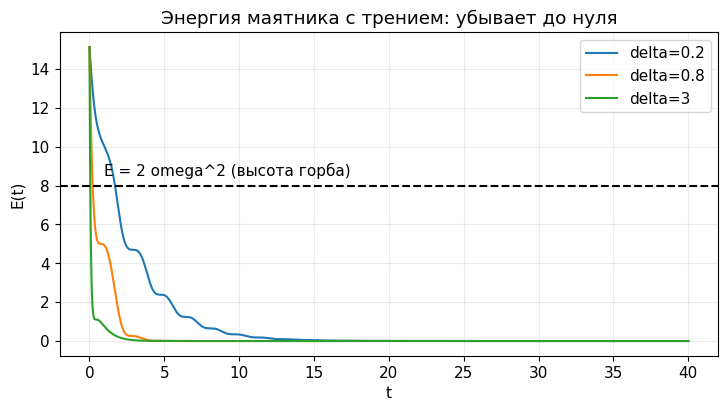

In [34]:
E = v**2/2 + w**2*(1 - sp.cos(x))
Edot = sp.diff(E, x)*F[0] + sp.diff(E, v)*F[1]
display(Math(r'\dot E=' + sp.latex(sp.simplify(Edot))))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for dl, c in zip(DELTAS_PEND, ['tab:blue', 'tab:orange', 'tab:green']):
    t, xx, vv = integrate(OMEGA_DAMP, dl, 'sin', 0.0, 5.5, 40, 6000)
    Et = energy(xx, vv, OMEGA_DAMP, 'sin')
    ax.plot(t, Et, color=c, label=f'delta={dl:g}')
    print(f'delta={dl:g}: E(0)-E(T) = {Et[0]-Et[-1]:.6f},  2*delta*int v^2 dt = {2*dl*np.trapezoid(vv**2, t):.6f}')
ax.axhline(2*OMEGA_DAMP**2, color='k', ls='--'); ax.text(1, 2*OMEGA_DAMP**2 + 0.5, 'E = 2 omega^2 (высота горба)')
ax.set_xlabel('t'); ax.set_ylabel('E(t)'); ax.set_title('Энергия маятника с трением: убывает до нуля'); ax.legend(); plt.show()

Пока $E>2\omega^2$, маятник вращается (энергии хватает преодолевать горбы). Как только энергия падает ниже $2\omega^2$, маятник **захватывается** одной из потенциальных ям и дальше колебания затухают. В какую именно яму он попадёт, зависит от начальных условий, это ключевая новая черта по сравнению с гармоническим осциллятором.

### 5.3. Фазовые портреты и сепаратрисы

Теперь у системы **несколько аттракторов**: устойчивые точки $(2k\pi,0)$. Каждая притягивает свою область, а границами областей служат **устойчивые многообразия седел** (кривые, входящие в седло). Их можно вычислить, запустив решение **назад по времени** из окрестности седла вдоль собственного вектора $(1,\lambda_s)$, где $\lambda_s=-\delta-\sqrt{\delta^2+\omega^2}<0$ — отрицательное собственное значение.

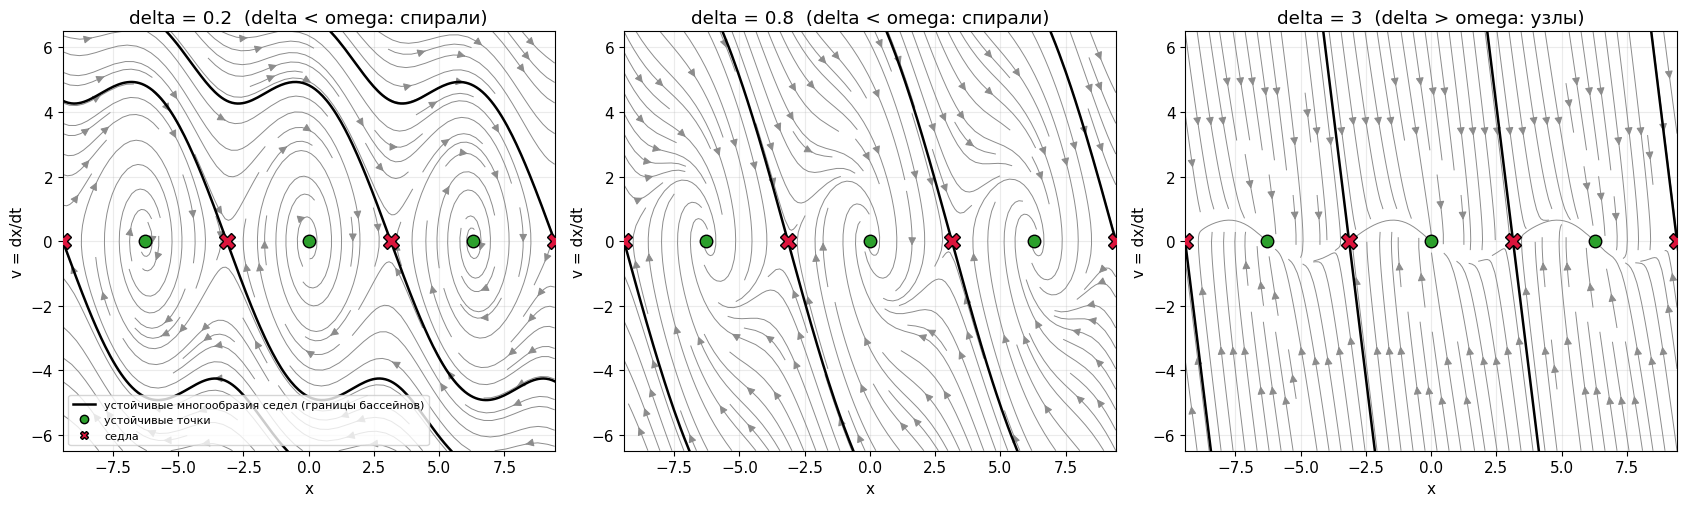

In [35]:
def stable_manifold(x_s, omega, delta, sign, vmax=7.0, T=100, eps=1e-6):
    """Ветвь устойчивого многообразия седла (x_s, 0): интегрирование назад по времени вдоль собственного вектора."""
    lam = -delta - np.sqrt(delta**2 + omega**2)
    vec = np.array([1.0, lam]); vec /= np.linalg.norm(vec)
    s0 = np.array([x_s, 0.0]) + sign*eps*vec
    def leave(t, s): return abs(s[1]) - vmax
    leave.terminal = True
    sol = solve_ivp(make_rhs(omega, delta, 'sin'), (0, -T), s0, events=leave, rtol=1e-10, atol=1e-12, max_step=0.05)
    return sol.y

def sep_curves(ax, omega, delta, xlim, vmax):
    for xs_, typ in equilibria('sin', xlim):
        if typ == 'max':
            for sg in (+1, -1):
                y = stable_manifold(xs_, omega, delta, sg, vmax=vmax)
                ax.plot(y[0], y[1], 'k', lw=1.8)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
om = OMEGA_DAMP
xlim, vlim = (-3*np.pi, 3*np.pi), (-6.5, 6.5)
for ax, dl in zip(axes, DELTAS_PEND):
    phase_background(ax, om, dl, 'sin', xlim, vlim, stream=True, density=1.4)
    sep_curves(ax, om, dl, xlim, vmax=vlim[1])
    mark_equilibria(ax, 'sin', dl, xlim)
    ax.set_title(f'delta = {dl:g}  ({"delta < omega: спирали" if dl < om else "delta > omega: узлы"})')
axes[0].legend(handles=[Line2D([], [], color='k', lw=1.8, label='устойчивые многообразия седел (границы бассейнов)'),
                        Line2D([], [], marker='o', ls='', color='tab:green', mec='k', label='устойчивые точки'),
                        Line2D([], [], marker='X', ls='', color='crimson', mec='k', label='седла')], loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

Чёрные линии — сепаратрисы (устойчивые многообразия седел), разделяющие бассейны притяжения соседних устойчивых точек. При слабом трении они **волнообразны** и идут почти вдоль линий уровня энергии (маятник теряет энергию медленно); чем сильнее трение, тем более прямыми и крутыми они становятся (при $\delta>\omega$ почти прямые), и бассейны превращаются в простые широкие полосы.

### 5.4. Карта бассейнов притяжения

Для каждой точки сетки начальных условий $(x_0,v_0)$ интегрируем систему достаточно долго и смотрим, к какому минимуму потенциала $x=2k\pi$ она пришла. Цвет показывает номер $k$. Для скорости счёта используется собственный векторизованный метод Рунге–Кутты 4-го порядка (сразу для всей сетки).

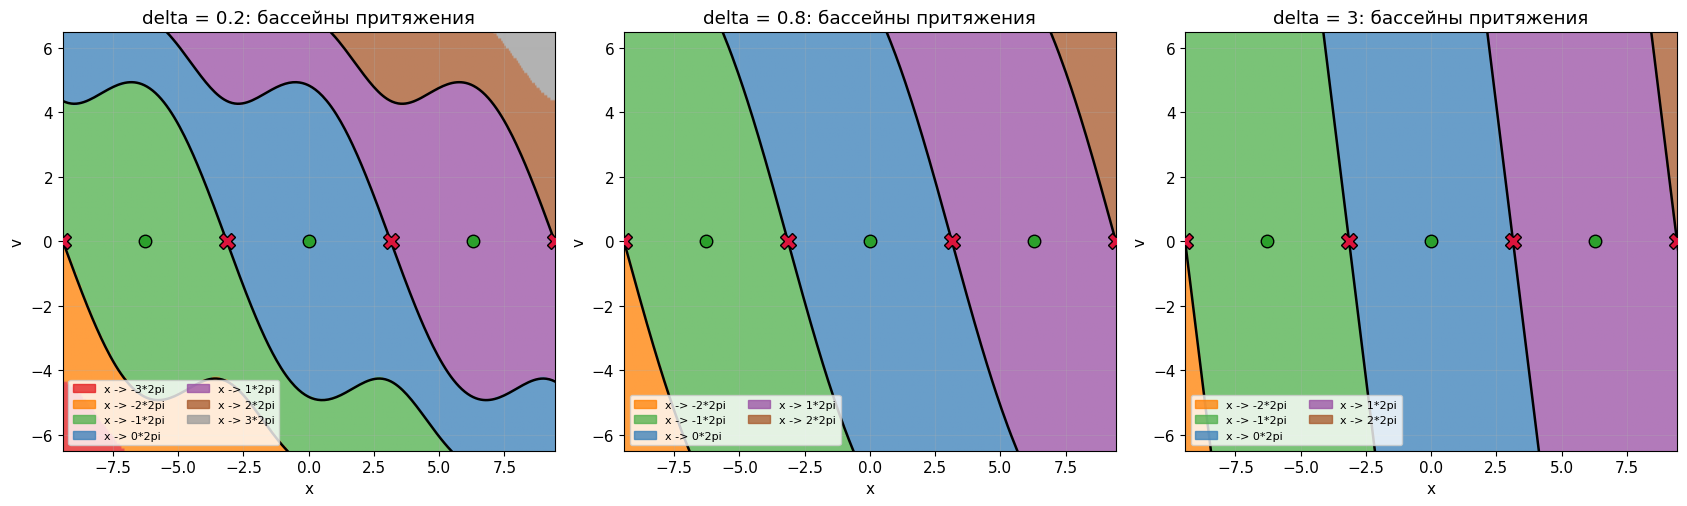

In [36]:
def rk4_final(omega, delta, X0, V0, T, dt=0.02):
    """Векторизованный RK4 для массива начальных условий: возвращает состояния в момент T."""
    x, v = X0.copy(), V0.copy()
    f = lambda x, v: (v, -2*delta*v - omega**2*np.sin(x))
    for _ in range(int(round(T/dt))):
        k1x, k1v = f(x, v)
        k2x, k2v = f(x + 0.5*dt*k1x, v + 0.5*dt*k1v)
        k3x, k3v = f(x + 0.5*dt*k2x, v + 0.5*dt*k2v)
        k4x, k4v = f(x + dt*k3x, v + dt*k3v)
        x += dt/6*(k1x + 2*k2x + 2*k3x + k4x)
        v += dt/6*(k1v + 2*k2v + 2*k3v + k4v)
    return x, v

def basin_map(omega, delta, xlim, vlim, nx=320, nv=170, T=60):
    xs = np.linspace(*xlim, nx); vs = np.linspace(*vlim, nv)
    X0, V0 = np.meshgrid(xs, vs)
    xf, vf = rk4_final(omega, delta, X0.ravel(), V0.ravel(), T)
    k = np.round(xf/(2*np.pi)).astype(int).reshape(X0.shape)
    return xs, vs, k

palette = ['#e41a1c', '#ff7f00', '#4daf4a', '#377eb8', '#984ea3', '#a65628', '#999999']
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
om = OMEGA_DAMP
xlim, vlim = (-3*np.pi, 3*np.pi), (-6.5, 6.5)
for ax, dl in zip(axes, DELTAS_PEND):
    xs, vs, k = basin_map(om, dl, xlim, vlim)
    kmin, kmax = k.min(), k.max()
    cmap = ListedColormap([palette[(kk + 3) % len(palette)] for kk in range(kmin, kmax + 1)])
    ax.imshow(k, origin='lower', extent=[*xlim, *vlim], aspect='auto', cmap=cmap, vmin=kmin - 0.5, vmax=kmax + 0.5, alpha=0.75)
    sep_curves(ax, om, dl, xlim, vmax=vlim[1])
    mark_equilibria(ax, 'sin', dl, xlim)
    ax.set_xlim(xlim); ax.set_ylim(vlim)
    ax.set_xlabel('x'); ax.set_ylabel('v')
    ax.set_title(f'delta = {dl:g}: бассейны притяжения')
    ax.legend(handles=[Patch(color=palette[(kk + 3) % len(palette)], alpha=.75, label=f'x -> {kk}*2pi') for kk in range(kmin, kmax + 1)],
              loc='lower left', fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Как читать карту.** Цвет точки — это яма, в которую она в итоге придёт (голубой — $x\to0$, соседние ямы — фиолетовый и зелёный, и так далее). Границы между цветами **совпадают с чёрными сепаратрисами**: это проверка того, что границы бассейнов — устойчивые многообразия седел. При слабом трении ($\delta=0{,}2$) быстрый маятник успевает пройти несколько горбов, прежде чем потеряет энергию, поэтому при больших $|v|$ появляются бассейны более далёких ям ($x\to\pm2\cdot2\pi$, $\pm3\cdot2\pi$), а границы между ними волнистые. При сильном трении полосы почти прямые, широкие и их число меньше.

### 5.5. Решения, графики $x(t)$, $\dot x(t)$ и контуры (пункты 5–6)

Три начальных условия при слабом трении: колебания внутри одной ямы, и два «разгона» с энергией выше горба. Для каждого определяем, в какую яму попал маятник.

старт (+1.0, +0.0), E0 =   1.84  ->  x(T) =  -0.0000 = 0*2pi,  конечная яма k = 0
старт (+0.0, +5.0), E0 =  12.50  ->  x(T) =  +6.2832 = 1*2pi,  конечная яма k = 1
старт (+0.0, +6.5), E0 =  21.12  ->  x(T) =  +6.2832 = 1*2pi,  конечная яма k = 1
старт (-1.0, -5.5), E0 =  16.96  ->  x(T) =  -6.2832 = -1*2pi,  конечная яма k = -1


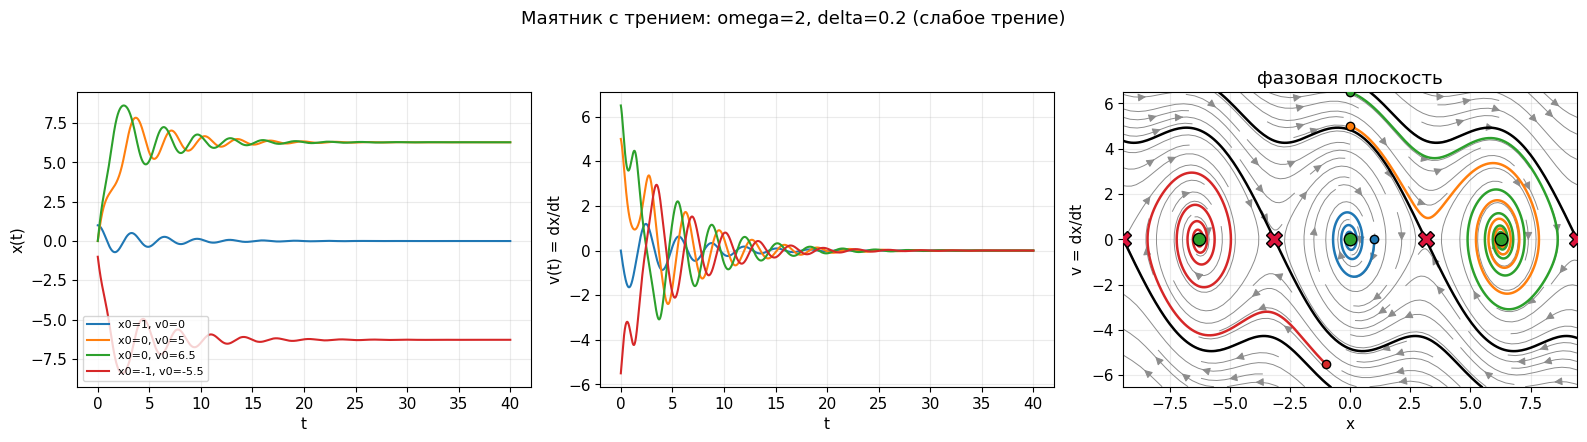

In [37]:
om, dl = OMEGA_DAMP, DELTAS_PEND[0]
ics = [(1.0, 0.0), (0.0, 5.0), (0.0, 6.5), (-1.0, -5.5)]
for (x0, v0) in ics:
    t, xx, vv = integrate(om, dl, 'sin', x0, v0, 80, 8000)
    kf = int(np.round(xx[-1]/(2*np.pi)))
    print(f'старт ({x0:+.1f}, {v0:+.1f}), E0 = {energy(x0, v0, om, "sin"):6.2f}  ->  x(T) = {xx[-1]:+8.4f} = {kf}*2pi,  конечная яма k = {kf}')
fig, ax = dynamics_figure(om, dl, 'sin', ics, T=40, n=6000, xlim=(-3*np.pi, 3*np.pi), vlim=(-6.5, 6.5),
                          title=f'Маятник с трением: omega={om:g}, delta={dl:g} (слабое трение)')
sep_curves(ax[2], om, dl, (-3*np.pi, 3*np.pi), 6.5)
plt.show()

Начальное условие $(1;0)$ — колебания внутри нулевой ямы с постепенным затуханием. Начальные условия с большой скоростью дают сначала **вращение** (кривая $x(t)$ растёт, пока энергия выше горба), потом захват в одну из ям и затухающие колебания. Видно, что $x(t)$ в итоге выходит на значения $2\pi k$ с разными $k$: физически это то же нижнее положение, но маятник мог совершить разное число оборотов.

Теперь то же при **сильном трении** ($\delta>\omega$): колебаний нет совсем, и траектории подходят к минимуму монотонно.

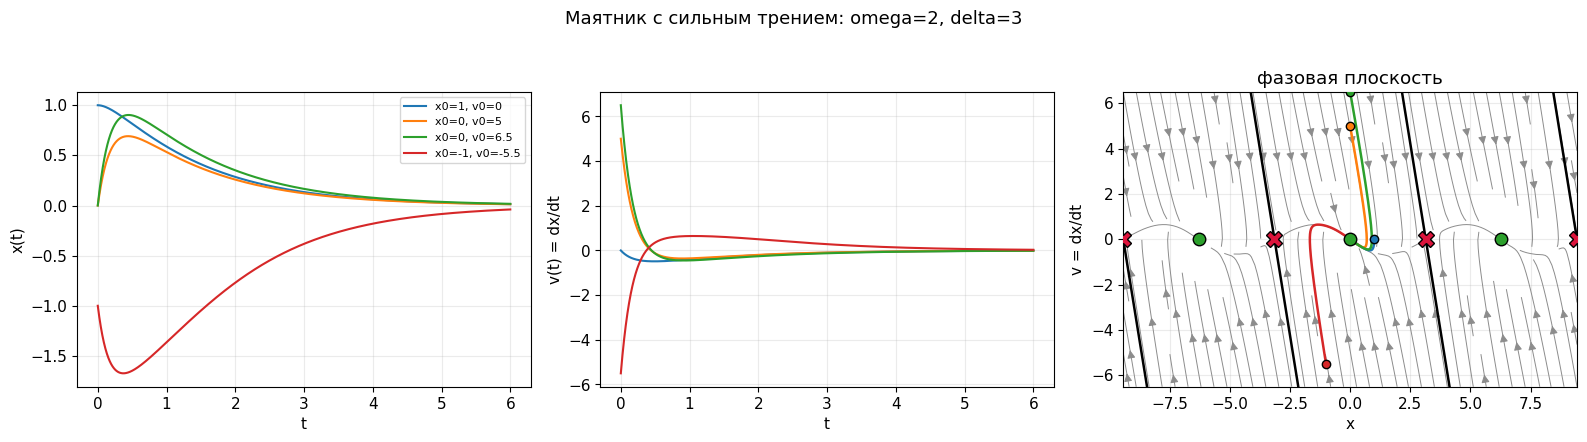

In [38]:
om, dl = OMEGA_DAMP, DELTAS_PEND[2]
ics = [(1.0, 0.0), (0.0, 5.0), (0.0, 6.5), (-1.0, -5.5)]
fig, ax = dynamics_figure(om, dl, 'sin', ics, T=6, n=3000, xlim=(-3*np.pi, 3*np.pi), vlim=(-6.5, 6.5),
                          title=f'Маятник с сильным трением: omega={om:g}, delta={dl:g}')
sep_curves(ax[2], om, dl, (-3*np.pi, 3*np.pi), 6.5)
plt.show()

### 5.6. Сжатие фазового объёма (нелинейная система)

Для маятника с трением $\operatorname{div}=-2\delta$ — **постоянная**, несмотря на нелинейность. Поэтому площадь любой области сжимается ровно как $e^{-2\delta t}$. А при $\delta=0$ площадь сохраняется (теорема Лиувилля), хотя форма области может сильно искажаться. Проверим численно на одном и том же облаке начальных условий.

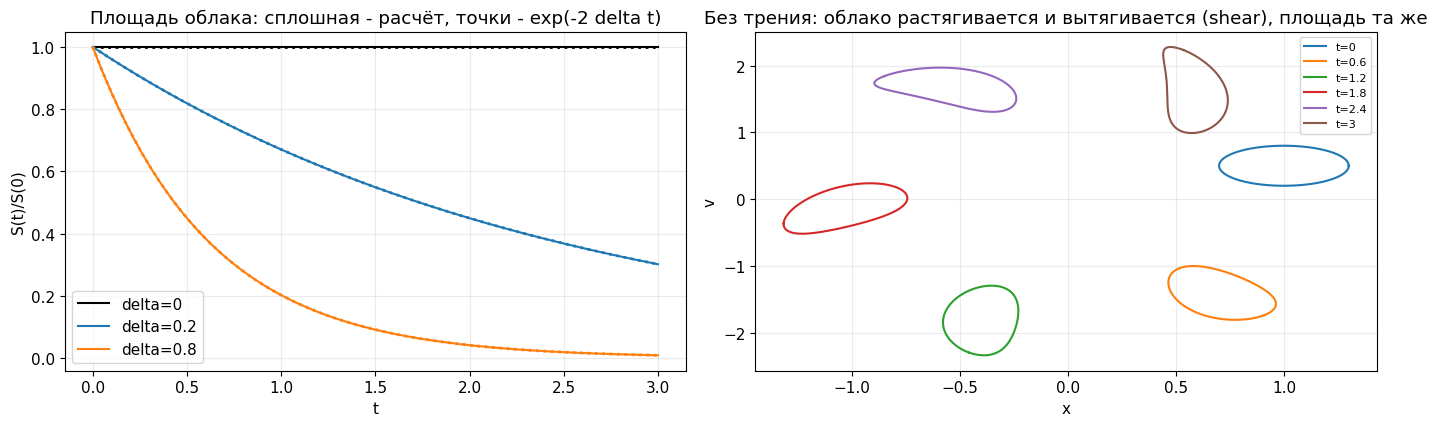

In [39]:
om = OMEGA_DAMP
tg = np.linspace(0, 3.0, 150)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for dl, c in zip([0.0] + DELTAS_PEND[:2], ['k', 'tab:blue', 'tab:orange']):
    S = area_ratio(om, dl, 'sin', (1.0, 0.5), 0.3, tg)
    ax[0].plot(tg, S, color=c, label=f'delta={dl:g}')
    ax[0].plot(tg, np.exp(-2*dl*tg), color=c, ls=':', lw=2)
ax[0].set_xlabel('t'); ax[0].set_ylabel('S(t)/S(0)'); ax[0].legend()
ax[0].set_title('Площадь облака: сплошная - расчёт, точки - exp(-2 delta t)')
th = np.linspace(0, 2*np.pi, 500, endpoint=False)
pts = np.column_stack([1.0 + 0.3*np.cos(th), 0.5 + 0.3*np.sin(th)])
tg2 = np.array([0, 0.6, 1.2, 1.8, 2.4, 3.0])
X, V = evolve_cloud(om, 0.0, 'sin', pts, tg2)
for i, tt in enumerate(tg2):
    ax[1].plot(np.append(X[i], X[i][0]), np.append(V[i], V[i][0]), label=f't={tt:g}')
ax[1].set_xlabel('x'); ax[1].set_ylabel('v'); ax[1].legend(fontsize=8)
ax[1].set_title('Без трения: облако растягивается и вытягивается (shear), площадь та же')
plt.tight_layout(); plt.show()

Без трения облако **не меняет площадь**, но сильно деформируется: в нелинейной системе период зависит от энергии, поэтому внутренние и внешние точки облака вращаются с разной скоростью и облако вытягивается в спираль. С трением к этому добавляется равномерное сжатие.

### 5.7. Выводы по разделу

* Верхнее положение — **седло** при любом трении; нижние положения — **асимптотически устойчивые** (фокус при $\delta<\omega$, узел при $\delta>\omega$). Центр, существовавший без трения, разрушается.
* Энергия убывает: $\dot E=-2\delta v^2$. Пока $E>2\omega^2$, маятник вращается, затем захватывается в яму и колебания затухают.
* У системы **много устойчивых состояний** (мультистабильность): яма $x=2k\pi$ выбирается начальными условиями. Границы бассейнов — устойчивые многообразия седел; при слабом трении они волнообразны, и из быстрого старта маятник может миновать много горбов, прежде чем осядет в одной из ям (итог тем чувствительнее к начальным условиям, чем ближе старт к границе бассейна).
* Фазовый объём сжимается как $e^{-2\delta t}$; замкнутых траекторий (в том числе предельных циклов) нет.

---
## 6. Сводка и общие выводы (пункт 7 задания)

### 6.1. Сравнительная таблица

| Свойство | Гарм. без трения | Гарм. с трением | Маятник без трения | Маятник с трением |
|---|---|---|---|---|
| Особые точки | $(0,0)$ | $(0,0)$ | $(k\pi,0)$ | $(k\pi,0)$ |
| Тип | центр | фокус / вырожд. узел / узел | центры (нижние) + седла (верхние) | устойчивые фокусы/узлы (нижние) + седла (верхние) |
| Устойчивость | по Ляпунову (не асимптотически) | асимптотически устойчива | центры по Ляпунову, седла неустойчивы | нижние асимптотически устойчивы, верхние неустойчивы |
| Энергия | $E=$ const | $\dot E=-2\delta v^2$ | $E=$ const | $\dot E=-2\delta v^2$ |
| Фазовый объём | сохраняется | $e^{-2\delta t}$ | сохраняется | $e^{-2\delta t}$ |
| Первый интеграл, потенциал | есть | нет (трение не потенциально) | есть | нет |
| Период | $2\pi/\omega$ (изохронность) | колебания затухают | растёт с амплитудой, $\to\infty$ у сепаратрисы | как у без трения, пока колебания, но затухающие |
| Число аттракторов | нет (консервативна) | 1 | нет | много (по одному на яму) |

Диаграмма «след–определитель» с нанесёнными точками наших систем ($\omega$ = `OMEGA_DAMP`):

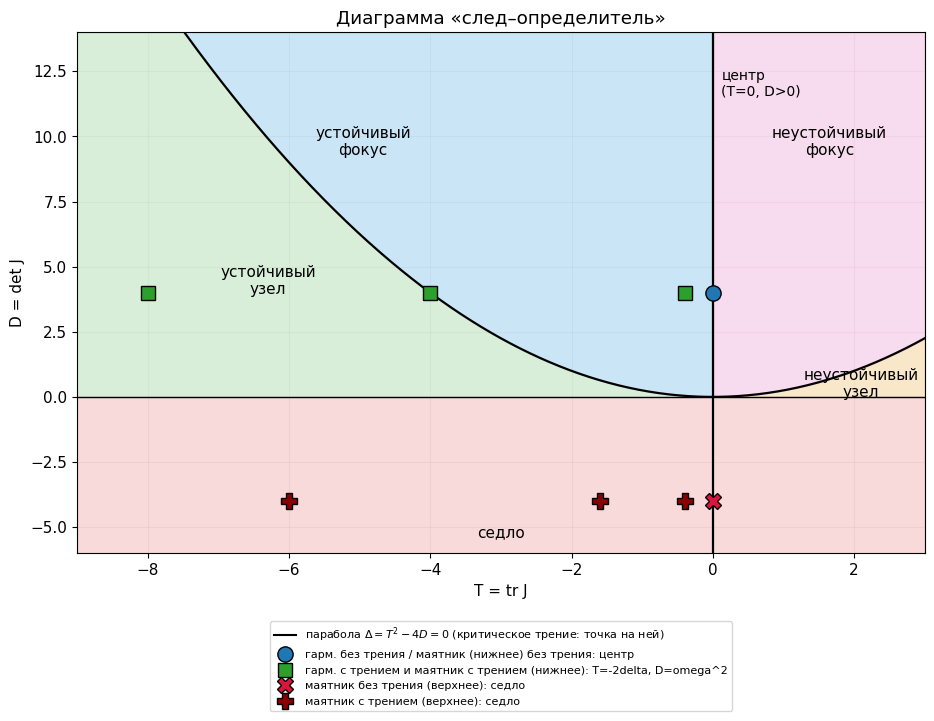

In [40]:
fig, ax = plt.subplots(figsize=(9.5, 7.4))
om = OMEGA_DAMP
td_diagram(ax, xlim=(-9, 3), ylim=(-6, 14), show_delta_label=False, saddle_pos=(-3.0, -5.2))
ax.plot([], [], 'k', label=r'парабола $\Delta=T^2-4D=0$ (критическое трение: точка на ней)')
ax.plot([0], [om**2], 'o', color='tab:blue', ms=11, mec='k', label='гарм. без трения / маятник (нижнее) без трения: центр')
ax.plot([-2*dl for dl in DELTAS], [om**2]*len(DELTAS), 's', color='tab:green', ms=10, mec='k', label='гарм. с трением и маятник с трением (нижнее): T=-2delta, D=omega^2')
ax.plot([0], [-om**2], 'X', color='crimson', ms=12, mec='k', label='маятник без трения (верхнее): седло')
ax.plot([-2*dl for dl in DELTAS_PEND], [-om**2]*len(DELTAS_PEND), 'P', color='darkred', ms=11, mec='k', label='маятник с трением (верхнее): седло')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12)); fig.tight_layout(); plt.show()

### 6.2. Общие выводы

1. **Линеаризация даёт локальную картину, но не всегда ответ.** Для седел и для устойчивых точек (все $\operatorname{Re}\lambda\ne0$) её достаточно. Для центров ($\operatorname{Re}\lambda=0$) нужны дополнительные средства. У консервативных систем это энергия.
2. **Энергия и потенциал связывают алгебру и геометрию.** Фазовый портрет консервативной системы — карта линий уровня энергии. Минимумы потенциала дают центры, максимумы — седла; горб высотой $2\omega^2$ у маятника задаёт сепаратрису и разделяет колебания и вращение.
3. **Нелинейность меняет качественную картину.** У гармонического осциллятора период не зависит от амплитуды и все движения «одинаковы». У маятника появляются неизохронность, сепаратриса, два принципиально разных режима движения (колебания и вращение).
4. **Трение — структурное возмущение.** Центр существует только при строго нулевом трении; любое $\delta>0$ превращает его в асимптотически устойчивую точку. Характер приближения (колебательный или монотонный) определяет отношение $\delta/\omega$.
5. **Диссипация — это сжатие фазового объёма.** Для всех рассмотренных систем $\operatorname{div}=-2\delta$, объём убывает как $e^{-2\delta t}$, замкнутых траекторий нет, а все траектории стремятся к устойчивым равновесиям (аттракторам).
6. **Мультистабильность.** У маятника с трением состояние покоя не единственно; какое из них реализуется, определяют начальные условия, а границы бассейнов — устойчивые многообразия седел. Чем слабее трение, тем больше горбов успевает пройти быстрый маятник и тем больше ям вовлечено в карту бассейнов.

### 6.3. Что включить в отчёт

* Для каждой из четырёх систем: уравнение, система первого порядка, особые точки (аналитически), матрица Якоби, собственные значения и тип точек, вывод об устойчивости (с оговоркой про центр).
* Для консервативных систем: первый интеграл, потенциал, 3D-поверхность энергии, фазовый портрет с направлением движения, связь экстремумов потенциала и типов точек.
* Для всех: графики $x(t)$, $\dot x(t)$ и контуры на фазовой плоскости для 2–3 значений параметров и разных начальных условий; краткий комментарий по каждому рисунку.
* Общие выводы (раздел 6.2).

---
## Приложение. Как заменить маятник на осциллятор Дуффинга

Если в вашем пособии ангармонический осциллятор задан уравнением $\ddot x+\omega^2x+\beta x^3=0$ (с трением $+2\delta\dot x$), нужно изменить только три места в ячейке «Вспомогательные функции»:

1. возвращающая сила: `g(x) = x + beta*x**3` вместо `np.sin(x)`;
2. потенциал: `U(x) = omega**2*(x**2/2 + beta*x**4/4)` вместо `omega**2*(1 - cos x)`;
3. список особых точек: $x^*=0$ и (при $\beta<0$) $x^*=\pm1/\sqrt{|\beta|}$.

Остальное (линеаризация, энергия, 3D-поверхность, портреты) работает без изменений. Качественная картина: при $\beta>0$ («жёсткая пружина») единственный центр, период убывает с ростом амплитуды; при $\beta<0$ («мягкая пружина») появляется потенциал с ямой и двумя горбами, центр в нуле, два седла в точках $\pm1/\sqrt{|\beta|}$ и сепаратриса, а вне неё траектории уходят в бесконечность. Для двуямного потенциала $\beta>0$, коэффициент перед $x$ отрицательный ($\ddot x-\omega^2x+\beta x^3=0$) — это седло в нуле и два центра.

**Если что-то не работает.**

* Ошибка `AttributeError: module 'numpy' has no attribute 'trapezoid'` — старая версия `numpy`; замените `np.trapezoid` на `np.trapz`.
* Карта бассейнов считается дольше всего (десятки секунд); уменьшите `nx`, `nv` или `T` в функции `basin_map`.
* Если 3D-поверхность не отображается — убедитесь, что установлен `%matplotlib inline` (или используйте `%matplotlib widget` для вращения мышью).